# India Data-Centre Resource Analysis — Final EDA

## Purpose

This notebook is the **final Exploratory Data Analysis (EDA)** notebook for the complete dataset package.

### EDA scope

1. Data validation and coverage
2. Renewable-energy capacity
3. Renewable-energy mix and solar/biomass breakdown
4. Renewable potential, headroom and utilization
5. Thermal / nuclear / hydro / non-fossil installed capacity
6. Regional electricity generation
7. Groundwater conditions and trends
8. Water-body distribution
9. Data-centre market distribution
10. Integrated state-level resource relationships
11. Optional state maps using the supplied GeoJSON
12. EDA findings and handoff notes


## 1. Imports and configuration

In [ ]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

sns.set_theme(style="whitegrid")

# IMPORTANT:
# Save this notebook in the same folder as all datasets.
DATA_DIR = Path("..").resolve()

FILES = {
    "states": "dim_state.csv",
    "geojson": "dim_state.geojson",
    "cea_capacity": "fact_cea_installed_capacity_features.csv",
    "datacentres": "fact_market_datacentres.csv",
    "re_breakdown": "fact_re_bio_solar_breakdown_2025.csv",
    "re_capacity": "fact_re_capacity_long.csv",
    "re_2025": "fact_re_state_2025.csv",
    "re_potential": "fact_re_state_potential.csv",
    "generation_daily": "fact_regional_generation_daily.csv",
    "generation_features": "fact_regional_generation_features.csv",
    "waterbodies": "fact_state_waterbodies.csv",
    "groundwater": "groundwater_features_final.csv",
    "mnre_features": "mnre_features.csv",
}

missing_files = [
    filename for filename in FILES.values()
    if filename != FILES["geojson"] and not (DATA_DIR / filename).exists()
]

if missing_files:
    raise FileNotFoundError(
        "The following files were not found in the notebook folder:\n"
        + "\n".join(missing_files)
    )

print("Notebook folder:", DATA_DIR)
print("All CSV files found.")


Notebook folder: C:\Users\ganes\Desktop\Clean Datasets
All CSV files found.


## 2. Load all datasets

In [2]:
states = pd.read_csv(DATA_DIR / FILES["states"])
cea_capacity = pd.read_csv(DATA_DIR / FILES["cea_capacity"])
datacentres = pd.read_csv(DATA_DIR / FILES["datacentres"])
re_breakdown = pd.read_csv(DATA_DIR / FILES["re_breakdown"])
re_capacity = pd.read_csv(DATA_DIR / FILES["re_capacity"])
re_2025 = pd.read_csv(DATA_DIR / FILES["re_2025"])
re_potential = pd.read_csv(DATA_DIR / FILES["re_potential"])
generation_daily = pd.read_csv(DATA_DIR / FILES["generation_daily"])
generation_features = pd.read_csv(DATA_DIR / FILES["generation_features"])
waterbodies = pd.read_csv(DATA_DIR / FILES["waterbodies"])
groundwater = pd.read_csv(DATA_DIR / FILES["groundwater"])
mnre_features = pd.read_csv(DATA_DIR / FILES["mnre_features"])

datasets = {
    "states": states,
    "cea_capacity": cea_capacity,
    "datacentres": datacentres,
    "re_breakdown": re_breakdown,
    "re_capacity": re_capacity,
    "re_2025": re_2025,
    "re_potential": re_potential,
    "generation_daily": generation_daily,
    "generation_features": generation_features,
    "waterbodies": waterbodies,
    "groundwater": groundwater,
    "mnre_features": mnre_features,
}

for name, df in datasets.items():
    print(f"{name:22s} {df.shape}")


states                 (36, 7)
cea_capacity           (175, 23)
datacentres            (34, 4)
re_breakdown           (36, 13)
re_capacity            (280, 5)
re_2025                (36, 9)
re_potential           (36, 9)
generation_daily       (4945, 8)
generation_features    (5, 14)
waterbodies            (36, 10)
groundwater            (717, 27)
mnre_features          (36, 16)


## 3. Dataset dictionary / structural overview

In [3]:
overview = []

for name, df in datasets.items():
    overview.append({
        "dataset": name,
        "rows": len(df),
        "columns": len(df.columns),
        "numeric_columns": len(df.select_dtypes(include=np.number).columns),
        "missing_cells": int(df.isna().sum().sum()),
        "duplicate_rows": int(df.duplicated().sum()),
    })

overview = pd.DataFrame(overview)
display(overview)


,dataset,rows,columns,numeric_columns,missing_cells,duplicate_rows
0,states,36,7,2,6,0
1,cea_capacity,175,23,20,159,0
2,datacentres,34,4,1,0,0
3,re_breakdown,36,13,11,0,0
4,re_capacity,280,5,1,0,0
5,re_2025,36,9,7,0,0
6,re_potential,36,9,7,0,0
7,generation_daily,4945,8,6,3956,0
8,generation_features,5,14,13,8,0
9,waterbodies,36,10,8,0,0


In [ ]:
for name, df in datasets.items():
    print("\n" + "=" * 100)
    print(name)
    print("=" * 100)
    print("Columns:")
    print(df.columns.tolist())
    print("\nFirst 3 rows:")
    display(df.head(3))

## 4. Data-quality report

The project requires checking missingness, duplicates, geographic coverage, time coverage and unusual values before analytical interpretation.

In [5]:
quality_rows = []

for name, df in datasets.items():
    missing_pct = df.isna().mean().mean() * 100
    quality_rows.append({
        "dataset": name,
        "rows": len(df),
        "columns": len(df.columns),
        "missing_cells": int(df.isna().sum().sum()),
        "missing_pct_of_all_cells": round(missing_pct, 2),
        "duplicate_rows": int(df.duplicated().sum()),
    })

quality_report = pd.DataFrame(quality_rows)
display(quality_report)


,dataset,rows,columns,missing_cells,missing_pct_of_all_cells,duplicate_rows
0,states,36,7,6,2.380,0
1,cea_capacity,175,23,159,3.950,0
2,datacentres,34,4,0,0.000,0
3,re_breakdown,36,13,0,0.000,0
4,re_capacity,280,5,0,0.000,0
5,re_2025,36,9,0,0.000,0
6,re_potential,36,9,0,0.000,0
7,generation_daily,4945,8,3956,10.000,0
8,generation_features,5,14,8,11.430,0
9,waterbodies,36,10,0,0.000,0


In [6]:
# Missing values by dataset
for name, df in datasets.items():
    missing = df.isna().sum()
    missing = missing[missing > 0].sort_values(ascending=False)
    if len(missing):
        print(f"\n{name}")
        display(missing.to_frame("missing_count"))



states


,missing_count
area_km2,2
region,2
national_share_pct,2



cea_capacity


,missing_count
coal_share_thermal_pct,31
gas_share_thermal_pct,31
diesel_share_thermal_pct,31
lignite_share_thermal_pct,31
thermal_share_pct,7
res_share_pct,7
nuclear_share_pct,7
hydro_share_pct,7
non_fossil_share_pct,7



generation_daily


...

,missing_count
nuclear_generation_mean_mu,2
nuclear_generation_std_mu,2
nuclear_estimated_diff_mean_mu,2
nuclear_generation_trend_mu_per_day,2



groundwater


,missing_count
GW_Recent_vs_Early_Change,31
GW_Mean_2015_2019,29
GW_Latest_2025,19
GW_Latest_Std_2025,19
GW_Latest_Median_2025,19
GW_Stations_2025,19
GW_2021_2025_Trend,10
GW_2021_2025_Std,10
GW_2015_2025_Trend,9
GW_2015_2025_Std,9



mnre_features


,missing_count
re_capacity_cagr_pct,2
re_capacity_growth_pct,2
re_capacity_2017_18_mw,1
re_capacity_growth_mw,1
re_capacity_2024_25_mw,1


## 5. State dimension validation

In [7]:
display(states)
print("Number of states/UTs:", states["state_id"].nunique())
print("Duplicate state IDs:", states["state_id"].duplicated().sum())
print("Duplicate state names:", states["state_name"].duplicated().sum())

print("\nRegions:")
display(states["region"].value_counts().to_frame("state_count"))


,state_id,state_name,shapeISO,shapeID,area_km2,region,national_share_pct
0,IN-PY,Puducherry,IN-PY,1811400B81659894240990,492.000,Southern,0.010
1,IN-MH,Maharashtra,IN-MH,1811400B15614733245507,"307,713.000",Western,9.360
2,IN-NL,Nagaland,IN-NL,1811400B74762431478096,"16,579.000",Northeastern,0.500
3,IN-LD,Lakshadweep,IN-LD,1811400B55669546485086,NaN,NaN,NaN
4,IN-UP,Uttar Pradesh,IN-UP,1811400B11231190780494,"240,928.000",Northern,7.330
5,IN-TN,Tamil Nadu,IN-TN,1811400B21167269026319,"130,058.000",Southern,3.950
6,IN-CT,Chhattisgarh,IN-CT,1811400B70654311394581,"135,191.000",Central,4.110
7,IN-GJ,Gujarat,IN-GJ,1811400B80305611676067,"196,024.000",Western,5.960
8,IN-DL,Delhi,IN-DL,1811400B23625213884851,"1,483.000",Northern,0.040
9,IN-SK,Sikkim,IN-SK,1811400B15456792557830,"7,096.000",Northeastern,0.210


Number of states/UTs: 36
Duplicate state IDs: 0
Duplicate state names: 0

Regions:


,state_count
region,
Northern,10
Northeastern,8
Southern,6
Western,4
Eastern,4
Central,2


# Renewable Energy EDA

## 6. Renewable capacity over time

`fact_re_capacity_long` contains state-level cumulative renewable capacity by financial year.

Main questions:
- How has aggregate renewable capacity changed?
- Which years show larger additions?
- Which states have the largest capacity?
- How different are state trajectories?


In [8]:
re_capacity["fiscal_year"] = re_capacity["fiscal_year"].astype(str)

national_re = (
    re_capacity
    .groupby("fiscal_year", as_index=False)["cumulative_re_capacity_mw"]
    .sum()
)

national_re["annual_addition_mw"] = national_re["cumulative_re_capacity_mw"].diff()
national_re["yoy_growth_pct"] = national_re["cumulative_re_capacity_mw"].pct_change() * 100

display(national_re)


,fiscal_year,cumulative_re_capacity_mw,annual_addition_mw,yoy_growth_pct
0,2017_18,"115,885.150",NaN,NaN
1,2018_19,"124,744.710","8,859.560",7.645
2,2019_20,"133,887.440","9,142.730",7.329
3,2020_21,"141,928.550","8,041.110",6.006
4,2021_22,"156,523.900","14,595.350",10.284
5,2022_23,"171,925.550","15,401.650",9.840
6,2023_24,"190,488.120","18,562.570",10.797
7,2024_25,"220,011.870","29,523.750",15.499


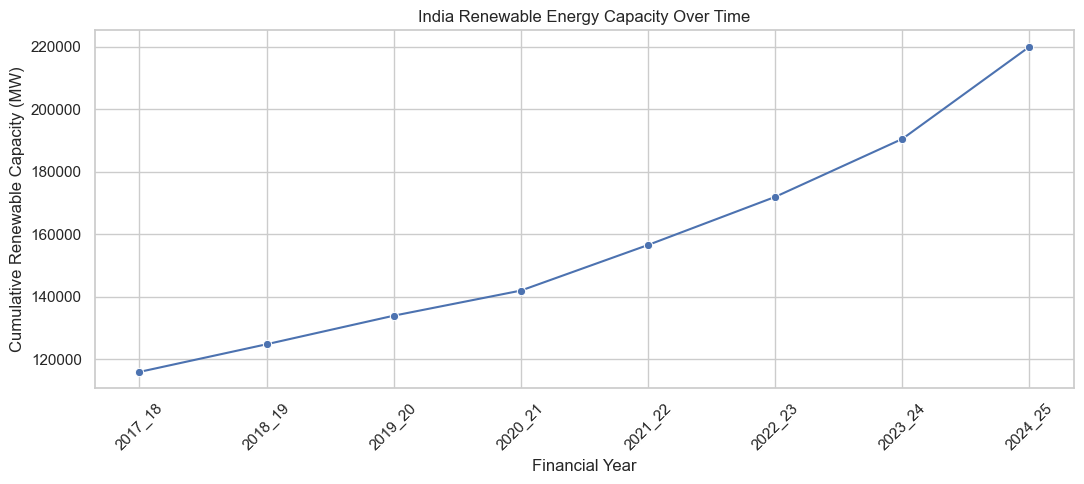

In [9]:
plt.figure(figsize=(11, 5))
sns.lineplot(
    data=national_re,
    x="fiscal_year",
    y="cumulative_re_capacity_mw",
    marker="o"
)
plt.title("India Renewable Energy Capacity Over Time")
plt.xlabel("Financial Year")
plt.ylabel("Cumulative Renewable Capacity (MW)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


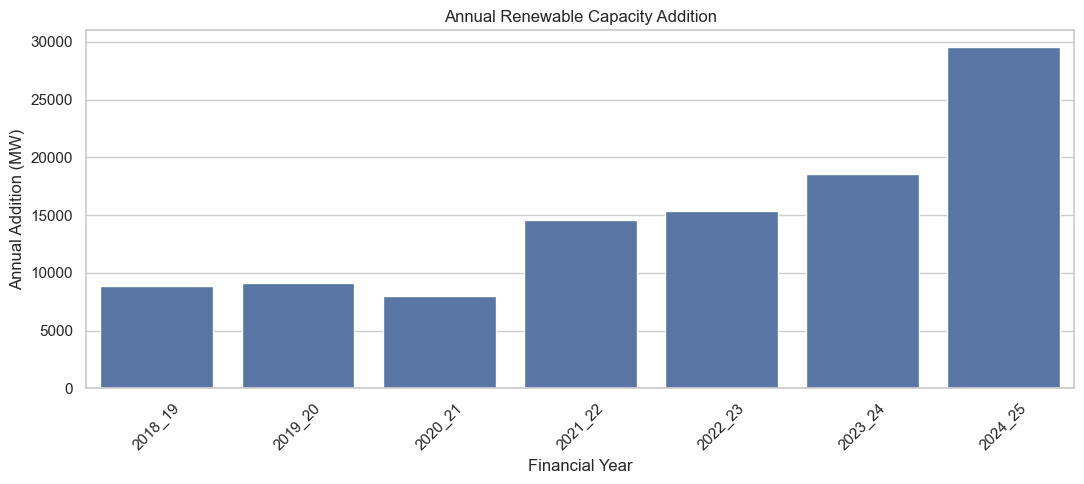

In [10]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(
    data=national_re.iloc[1:],
    x="fiscal_year",
    y="annual_addition_mw",
    ax=ax
)
ax.set_title("Annual Renewable Capacity Addition")
ax.set_xlabel("Financial Year")
ax.set_ylabel("Annual Addition (MW)")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


## 7. State-wise renewable capacity

In [11]:
latest_re_year = re_capacity["fiscal_year"].iloc[-1]

latest_re = (
    re_capacity[re_capacity["fiscal_year"] == latest_re_year]
    .sort_values("cumulative_re_capacity_mw", ascending=False)
)

display(latest_re.head(15))


,state_id,state_name,region,fiscal_year,cumulative_re_capacity_mw
250,IN-RJ,Rajasthan,Northern Region,2024_25,"34,136.340"
264,IN-GJ,Gujarat,Western Region,2024_25,"33,393.030"
276,IN-TN,Tamil Nadu,Southern Region,2024_25,"25,241.360"
274,IN-KA,Karnataka,Southern Region,2024_25,"23,917.640"
266,IN-MH,Maharashtra,Western Region,2024_25,"22,401.460"
246,IN-HP,Himachal Pradesh,Northern Region,2024_25,"12,196.180"
273,IN-AP,Andhra Pradesh,Southern Region,2024_25,"12,114.480"
265,IN-MP,Madhya Pradesh,Western Region,2024_25,"10,827.700"
277,IN-TG,Telangana,Southern Region,2024_25,"7,688.340"
251,IN-UP,Uttar Pradesh,Northern Region,2024_25,"6,223.910"


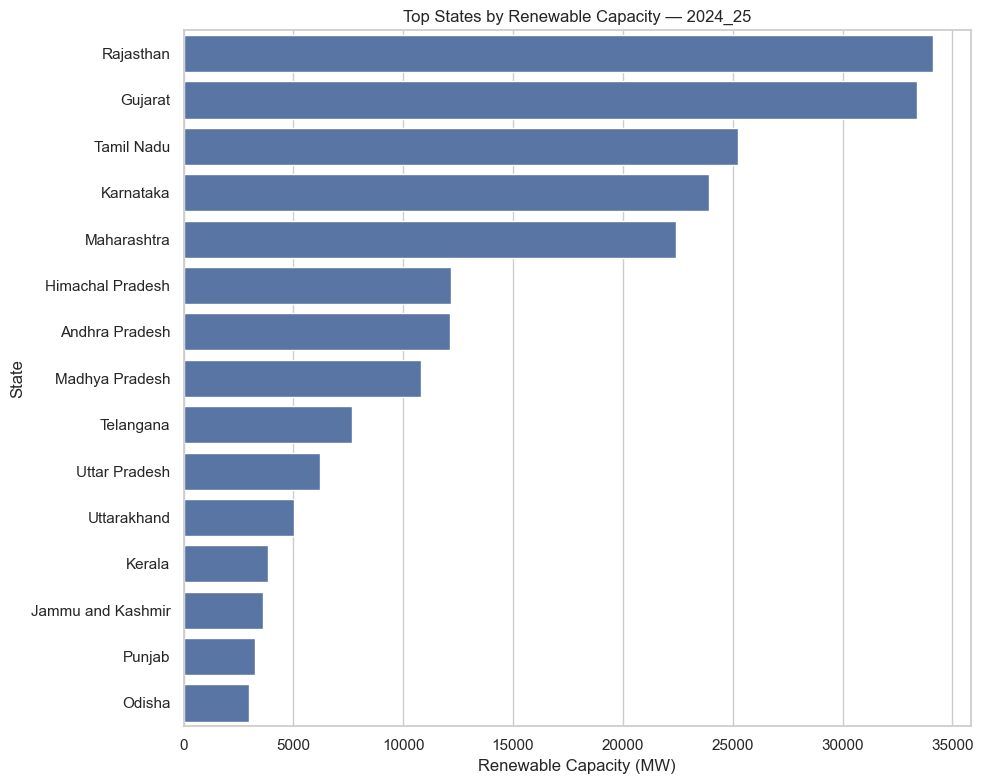

In [12]:
plt.figure(figsize=(10, 8))
sns.barplot(
    data=latest_re.head(15),
    y="state_name",
    x="cumulative_re_capacity_mw"
)
plt.title(f"Top States by Renewable Capacity — {latest_re_year}")
plt.xlabel("Renewable Capacity (MW)")
plt.ylabel("State")
plt.tight_layout()
plt.show()


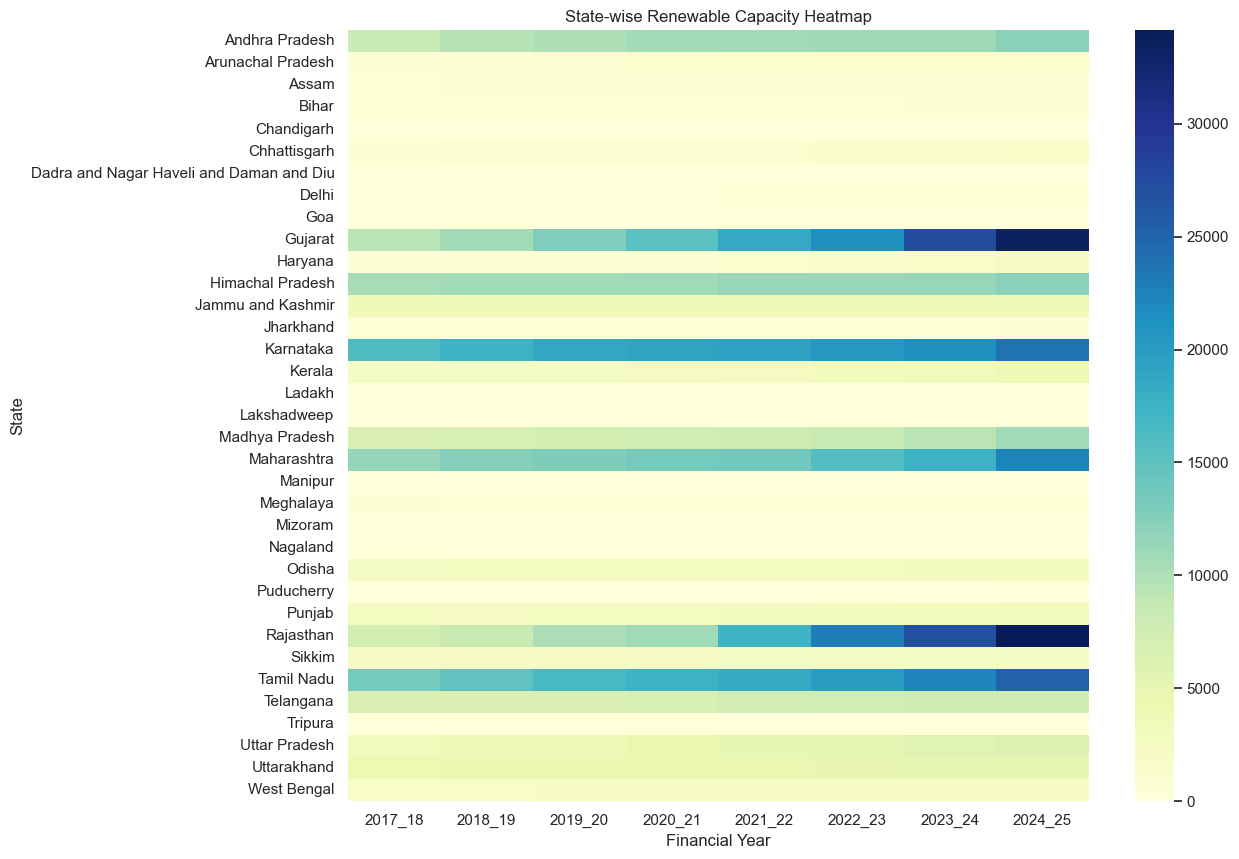

In [13]:
capacity_pivot = re_capacity.pivot_table(
    index="state_name",
    columns="fiscal_year",
    values="cumulative_re_capacity_mw",
    aggfunc="sum"
)

plt.figure(figsize=(13, max(8, len(capacity_pivot) * 0.25)))
sns.heatmap(capacity_pivot, cmap="YlGnBu")
plt.title("State-wise Renewable Capacity Heatmap")
plt.xlabel("Financial Year")
plt.ylabel("State")
plt.tight_layout()
plt.show()


In [14]:
growth_re = (
    re_capacity
    .sort_values(["state_name", "fiscal_year"])
    .groupby("state_name")
    .agg(
        start_capacity_mw=("cumulative_re_capacity_mw", "first"),
        end_capacity_mw=("cumulative_re_capacity_mw", "last")
    )
    .reset_index()
)

growth_re["absolute_growth_mw"] = (
    growth_re["end_capacity_mw"] - growth_re["start_capacity_mw"]
)
growth_re["growth_pct"] = (
    growth_re["absolute_growth_mw"] /
    growth_re["start_capacity_mw"].replace(0, np.nan) * 100
)

display(growth_re.sort_values("absolute_growth_mw", ascending=False).head(15))


,state_name,start_capacity_mw,end_capacity_mw,absolute_growth_mw,growth_pct
27,Rajasthan,"7,289.360","34,136.340","26,846.980",368.304
9,Gujarat,"9,339.450","33,393.030","24,053.580",257.548
29,Tamil Nadu,"13,451.700","25,241.360","11,789.660",87.644
19,Maharashtra,"11,519.210","22,401.460","10,882.250",94.470
14,Karnataka,"16,241.600","23,917.640","7,676.040",47.262
18,Madhya Pradesh,"6,445.130","10,827.700","4,382.570",67.998
0,Andhra Pradesh,"8,060.580","12,114.480","4,053.900",50.293
32,Uttar Pradesh,"3,447.250","6,223.910","2,776.660",80.547
10,Haryana,510.490,"2,449.940","1,939.450",379.919
11,Himachal Pradesh,"10,514.300","12,196.180","1,681.880",15.996


## 8. Renewable mix — 2025

In [15]:
mix_cols = [
    "Small_Hydro_MW",
    "Wind_Power_MW",
    "Bio_Power_MW",
    "Solar_Power_MW",
    "Large_Hydro_MW"
]

mix_totals = re_2025[mix_cols].sum().sort_values(ascending=False)
display(mix_totals.to_frame("total_capacity_mw"))


,total_capacity_mw
Solar_Power_MW,"105,601.480"
Wind_Power_MW,"50,033.520"
Large_Hydro_MW,"47,728.170"
Bio_Power_MW,"11,583.320"
Small_Hydro_MW,"5,100.550"


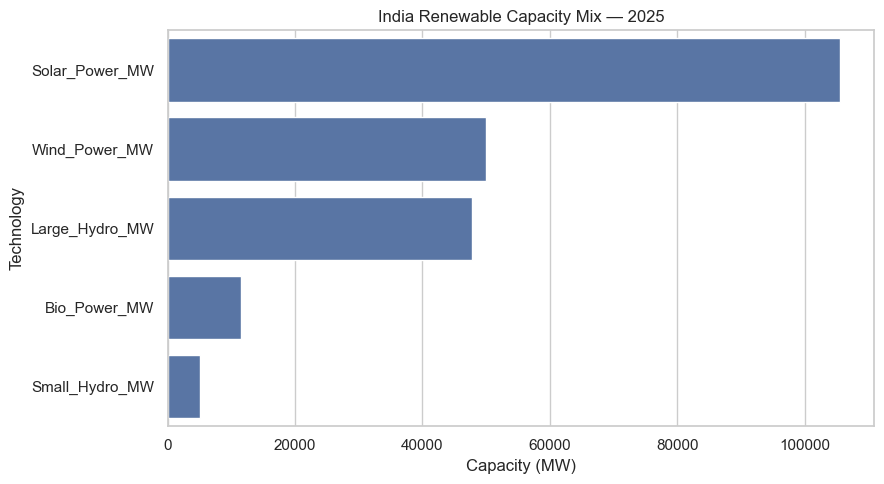

In [16]:
plt.figure(figsize=(9, 5))
sns.barplot(x=mix_totals.values, y=mix_totals.index)
plt.title("India Renewable Capacity Mix — 2025")
plt.xlabel("Capacity (MW)")
plt.ylabel("Technology")
plt.tight_layout()
plt.show()


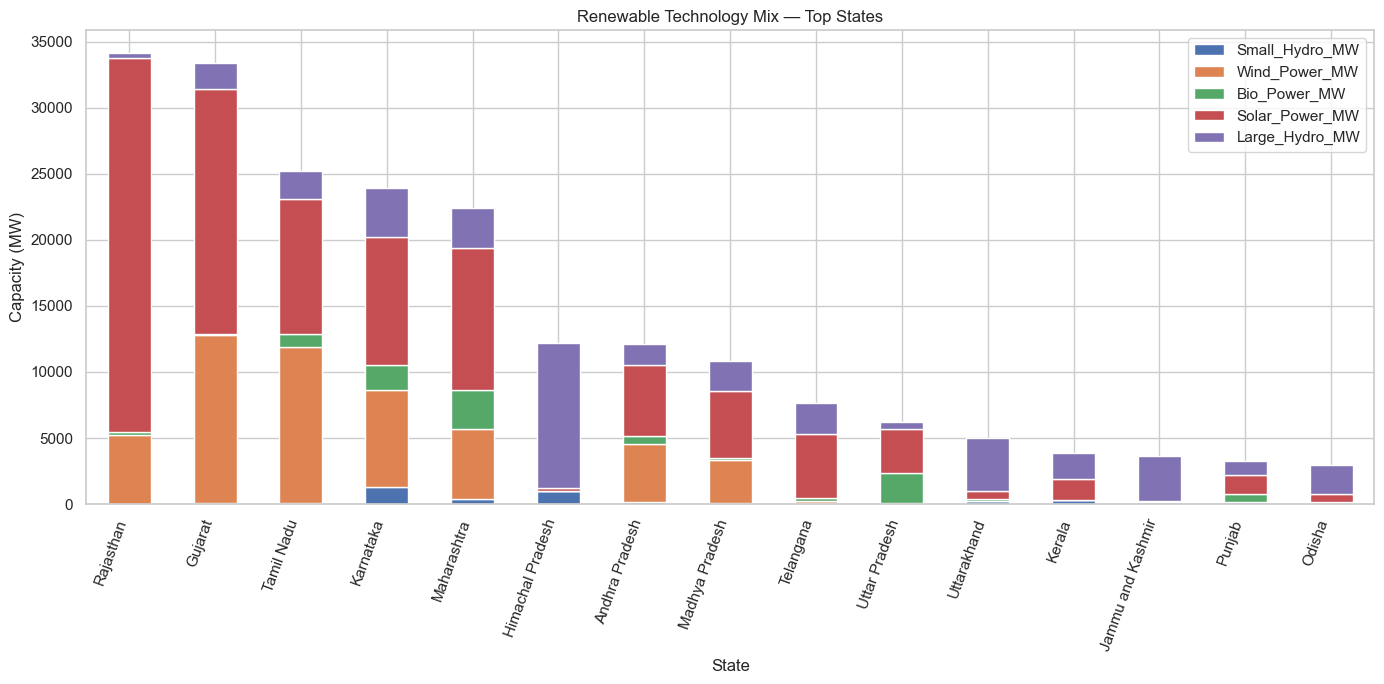

In [17]:
top_mix = re_2025.copy()
top_mix["Total_RES_MW"] = top_mix["Total_RES_MW"].fillna(
    top_mix[mix_cols].sum(axis=1)
)
top_mix = top_mix.sort_values("Total_RES_MW", ascending=False).head(15)

top_mix.set_index("state_name")[mix_cols].plot(
    kind="bar",
    stacked=True,
    figsize=(14, 7)
)
plt.title("Renewable Technology Mix — Top States")
plt.xlabel("State")
plt.ylabel("Capacity (MW)")
plt.xticks(rotation=70, ha="right")
plt.tight_layout()
plt.show()


## 9. Solar, biomass and waste-to-energy breakdown

This is a deeper technology-level EDA for the 2025 renewable snapshot.

In [18]:
breakdown_cols = [
    "biomass_bagasse_cogen_mw",
    "biomass_non_bagasse_cogen_mw",
    "waste_to_energy_grid_mw",
    "waste_to_energy_offgrid_mw",
    "solar_ground_mounted_mw",
    "solar_rooftop_mw",
    "solar_hybrid_component_mw",
    "solar_offgrid_kusum_mw"
]

breakdown_totals = re_breakdown[breakdown_cols].sum().sort_values(ascending=False)
display(breakdown_totals.to_frame("total_mw"))


,total_mw
solar_ground_mounted_mw,"81,011.660"
solar_rooftop_mw,"15,501.640"
biomass_bagasse_cogen_mw,"9,821.320"
solar_offgrid_kusum_mw,"3,697.880"
solar_hybrid_component_mw,"1,874.500"
biomass_non_bagasse_cogen_mw,921.790
waste_to_energy_offgrid_mw,530.870
waste_to_energy_grid_mw,309.340


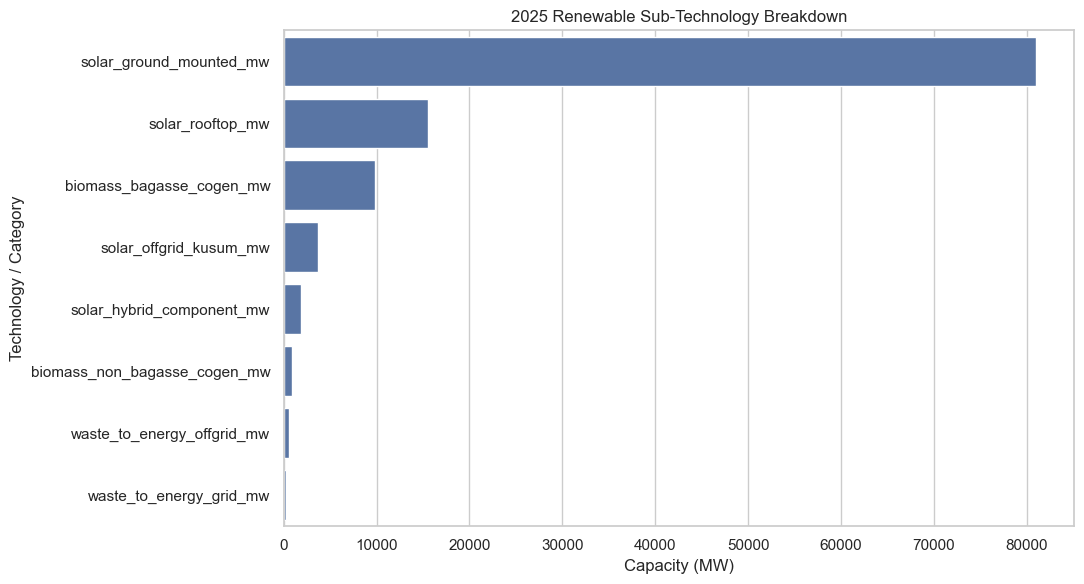

In [19]:
plt.figure(figsize=(11, 6))
sns.barplot(x=breakdown_totals.values, y=breakdown_totals.index)
plt.title("2025 Renewable Sub-Technology Breakdown")
plt.xlabel("Capacity (MW)")
plt.ylabel("Technology / Category")
plt.tight_layout()
plt.show()


## 10. Renewable potential, headroom and utilization

In [20]:
potential_cols = [
    "wind_potential_mw",
    "small_hydro_potential_mw",
    "biomass_potential_mw",
    "bagasse_cogen_potential_mw",
    "solar_ground_potential_mw",
    "large_hydro_potential_mw",
]

potential_totals = re_potential[potential_cols].sum().sort_values(ascending=False)
display(potential_totals.to_frame("estimated_potential"))


,estimated_potential
solar_ground_potential_mw,"3,338,942.150"
wind_potential_mw,"1,163,839.000"
large_hydro_potential_mw,"123,410.030"
biomass_potential_mw,"28,444.760"
small_hydro_potential_mw,"21,133.620"
bagasse_cogen_potential_mw,"13,534.000"


,state_name,total_re_potential_mw
22,Rajasthan,"1,114,793.660"
15,Maharashtra,"671,023.690"
6,Gujarat,"427,954.410"
0,Andhra Pradesh,"427,932.530"
12,Karnataka,"404,226.860"
14,Madhya Pradesh,"380,551.020"
24,Tamil Nadu,"304,461.100"
25,Telangana,"198,368.270"
20,Odisha,"155,012.770"
4,Chhattisgarh,"131,996.170"


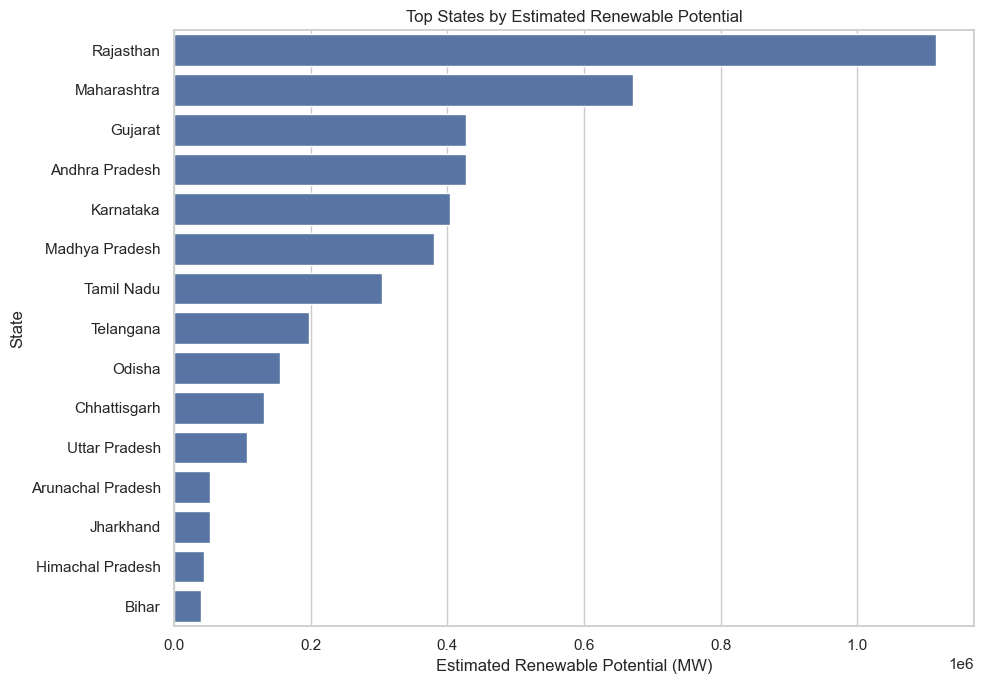

In [21]:
top_potential = re_potential.sort_values(
    "total_re_potential_mw", ascending=False
).head(15)

display(
    top_potential[
        ["state_name", "total_re_potential_mw"]
    ]
)

plt.figure(figsize=(10, 7))
sns.barplot(
    data=top_potential,
    y="state_name",
    x="total_re_potential_mw"
)
plt.title("Top States by Estimated Renewable Potential")
plt.xlabel("Estimated Renewable Potential (MW)")
plt.ylabel("State")
plt.tight_layout()
plt.show()


In [22]:
feature_cols = [
    "renewable_headroom_mw",
    "renewable_utilization_pct",
    "re_capacity_growth_mw",
    "re_capacity_growth_pct",
    "re_capacity_cagr_pct"
]

display(
    mnre_features[
        ["state_name"] + feature_cols
    ].sort_values("renewable_headroom_mw", ascending=False).head(15)
)


,state_name,renewable_headroom_mw,renewable_utilization_pct,re_capacity_growth_mw,re_capacity_growth_pct,re_capacity_cagr_pct
22,Rajasthan,"1,080,657.320",3.062,"26,846.980",368.304,24.678
15,Maharashtra,"648,622.230",3.338,"10,882.250",94.470,9.968
0,Andhra Pradesh,"415,818.050",2.831,"4,053.900",50.293,5.993
6,Gujarat,"394,561.380",7.803,"24,053.580",257.548,19.963
11,Karnataka,"380,309.220",5.917,"7,676.040",47.262,5.685
14,Madhya Pradesh,"369,723.320",2.845,"4,382.570",67.998,7.693
24,Tamil Nadu,"279,219.740",8.291,"11,789.660",87.644,9.408
25,Telangana,"190,679.930",3.876,"1,180.860",18.146,2.411
20,Odisha,"152,053.930",1.909,593.900,25.113,3.252
4,Chhattisgarh,"130,167.710",1.385,"1,043.040",132.800,12.830


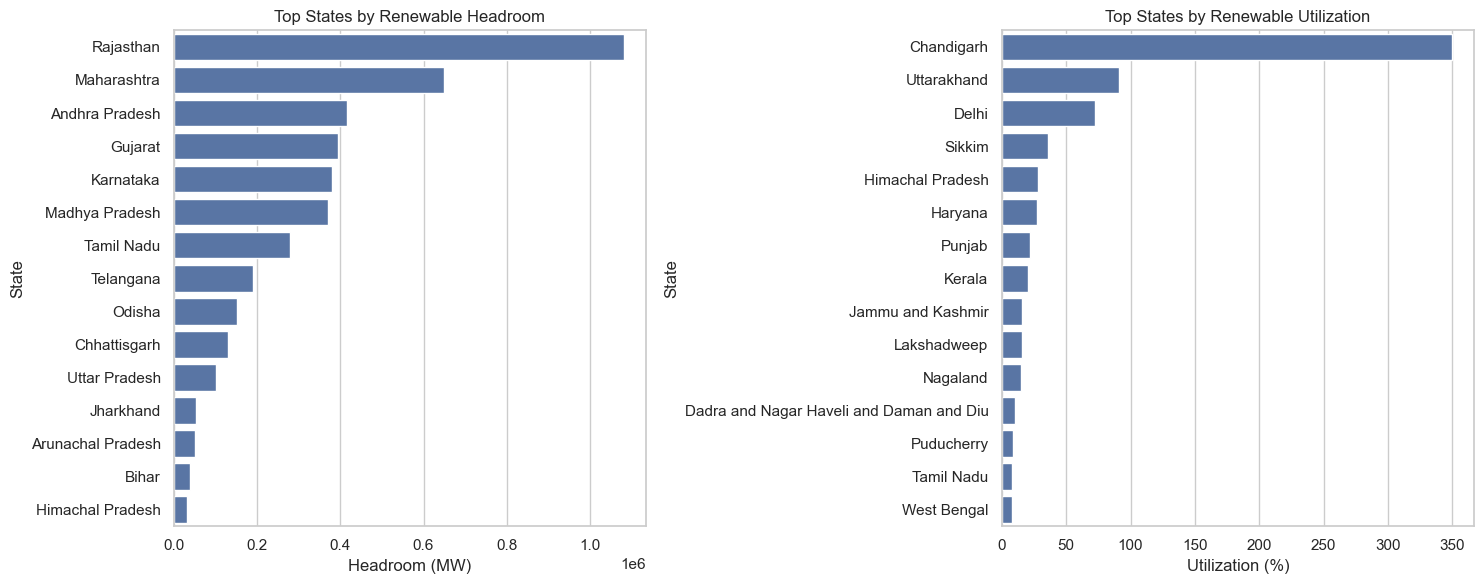

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

headroom_top = mnre_features.sort_values(
    "renewable_headroom_mw", ascending=False
).head(15)

sns.barplot(
    data=headroom_top,
    y="state_name",
    x="renewable_headroom_mw",
    ax=axes[0]
)
axes[0].set_title("Top States by Renewable Headroom")
axes[0].set_xlabel("Headroom (MW)")
axes[0].set_ylabel("State")

util_top = mnre_features.sort_values(
    "renewable_utilization_pct", ascending=False
).head(15)

sns.barplot(
    data=util_top,
    y="state_name",
    x="renewable_utilization_pct",
    ax=axes[1]
)
axes[1].set_title("Top States by Renewable Utilization")
axes[1].set_xlabel("Utilization (%)")
axes[1].set_ylabel("State")

plt.tight_layout()
plt.show()


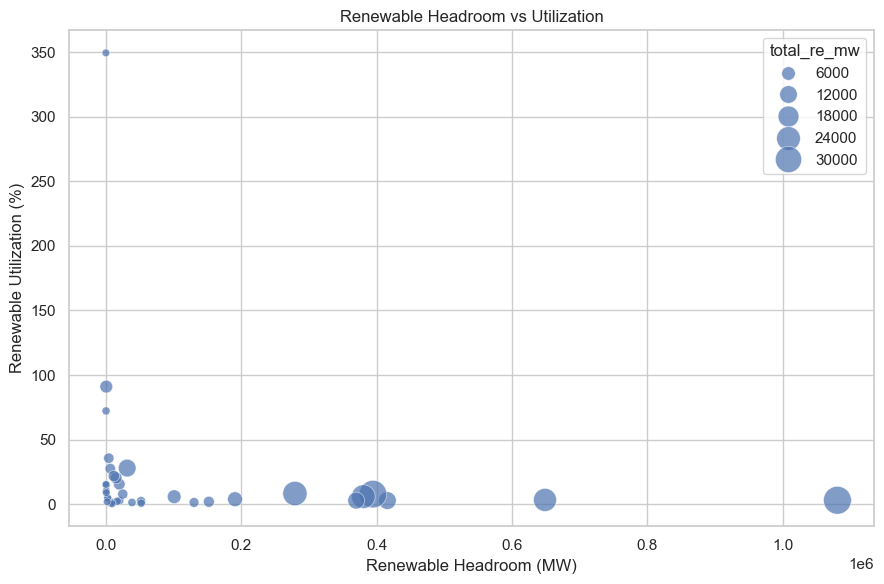

In [24]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=mnre_features,
    x="renewable_headroom_mw",
    y="renewable_utilization_pct",
    size="total_re_mw",
    sizes=(30, 400),
    alpha=0.7
)
plt.title("Renewable Headroom vs Utilization")
plt.xlabel("Renewable Headroom (MW)")
plt.ylabel("Renewable Utilization (%)")
plt.tight_layout()
plt.show()


# Thermal / Installed Capacity EDA

## 11. CEA installed-capacity data quality

The CEA dataset contains region/sector/aggregate rows as well as state-related labels. The `State_UT` field includes aggregate labels such as `Total (...)`, and some state names appear truncated/misaligned.

Therefore:
- Use **regional aggregate rows** for regional CEA analysis.
- Do not silently treat every `State_UT` value as a clean state.
- The notebook explicitly identifies suspicious labels.


In [25]:
display(cea_capacity["Sector"].value_counts().to_frame("rows"))
display(cea_capacity["Region"].value_counts().to_frame("rows"))

suspicious_cea = cea_capacity[
    cea_capacity["State_UT"].astype(str).str.contains(
        "Total|Region|and Diu|Eastern Region|Western Region|Southern Region",
        case=False,
        na=False
    )
]

print("Potential aggregate/malformed State_UT labels:")
display(suspicious_cea[["Region", "State_UT", "Sector"]].drop_duplicates())


,rows
Sector,
Central,47
Private,43
State,42
Sub-Total,37
Grand Total,6


,rows
Region,
Northern Region,41
Southern Region,33
North Eastern Region,33
Eastern Region,29
Western Region,28
Islands,11


Potential aggregate/malformed State_UT labels:


,Region,State_UT,Sector
0,Northern Region,Northern Region,State
1,Northern Region,Northern Region,Private
2,Northern Region,Northern Region,Central
3,Northern Region,Northern Region,Sub-Total
38,Northern Region,Total (Northern,Private
39,Northern Region,Region),Central
40,Northern Region,Region),Grand Total
41,Western Region,Western Region,State
42,Western Region,Western Region,Private
43,Western Region,Western Region,Central


## 12. Regional installed-capacity composition

For this EDA, `Sector == "Grand Total"` is used to compare the six regional aggregate rows.

In [26]:
cea_region_total = cea_capacity[
    cea_capacity["Sector"].eq("Grand Total")
].copy()

display(
    cea_region_total[
        [
            "Region",
            "Thermal_Total_MW",
            "Nuclear_MW",
            "Hydro_MW",
            "RES_MNRE_MW",
            "Total_RES_incl_Hydro_MW",
            "Grand_Total_MW",
            "non_fossil_capacity_mw",
            "non_fossil_share_pct"
        ]
    ]
)


,Region,Thermal_Total_MW,Nuclear_MW,Hydro_MW,RES_MNRE_MW,Total_RES_incl_Hydro_MW,Grand_Total_MW,non_fossil_capacity_mw,non_fossil_share_pct
40,Northern Region,"69,553.000","2,220.000","22,959.670","67,699.340","90,659.010","162,432.010","92,879.010",57.180
68,Western Region,"84,212.120","3,240.000","8,094.080","93,959.190","102,053.270","189,505.390","105,293.270",55.562
101,Southern Region,"61,782.810","3,320.000","13,676.480","73,481.130","87,157.610","152,260.420","90,477.610",59.423
130,Eastern Region,"33,007.680",0.000,"4,862.420","3,265.420","8,127.840","41,135.520","8,127.840",19.759
163,North Eastern Region,"2,813.970",0.000,"2,472.010","1,208.550","3,680.560","6,494.530","3,680.560",56.672
174,Islands,119.540,0.000,0.000,47.340,47.340,166.880,47.340,28.368


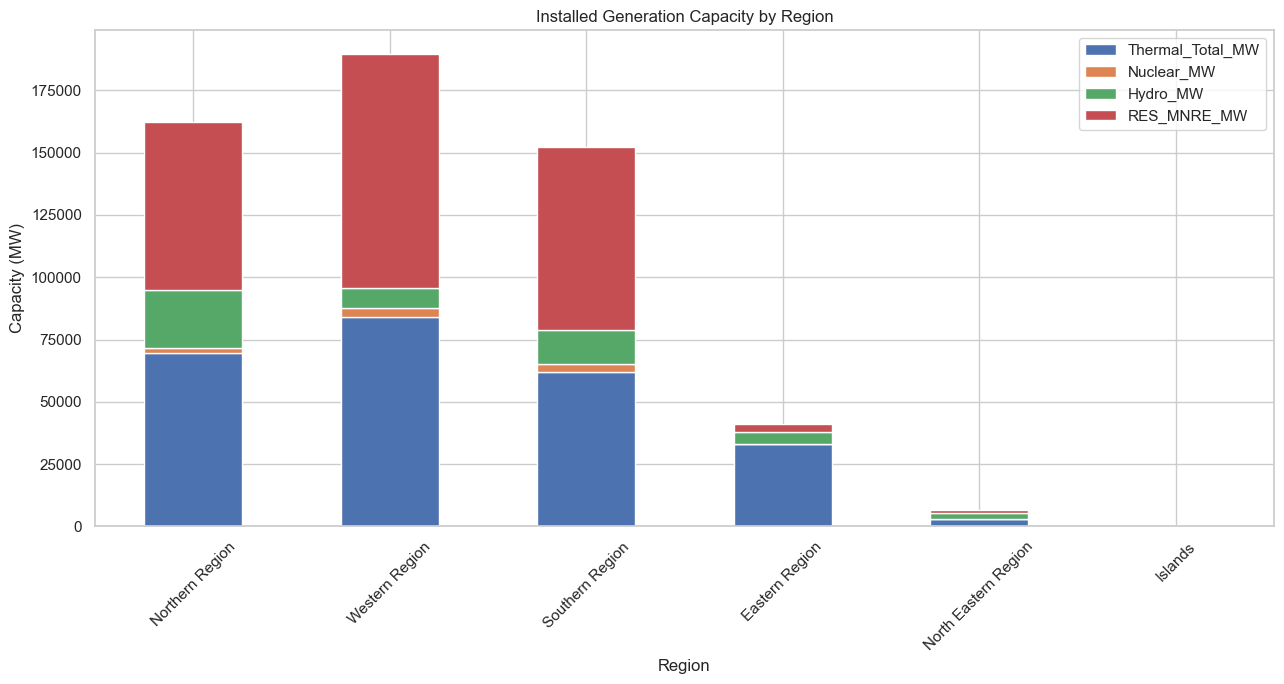

In [27]:
plot_cols = [
    "Thermal_Total_MW",
    "Nuclear_MW",
    "Hydro_MW",
    "RES_MNRE_MW"
]

cea_region_plot = cea_region_total.set_index("Region")[plot_cols]

cea_region_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 7)
)
plt.title("Installed Generation Capacity by Region")
plt.xlabel("Region")
plt.ylabel("Capacity (MW)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


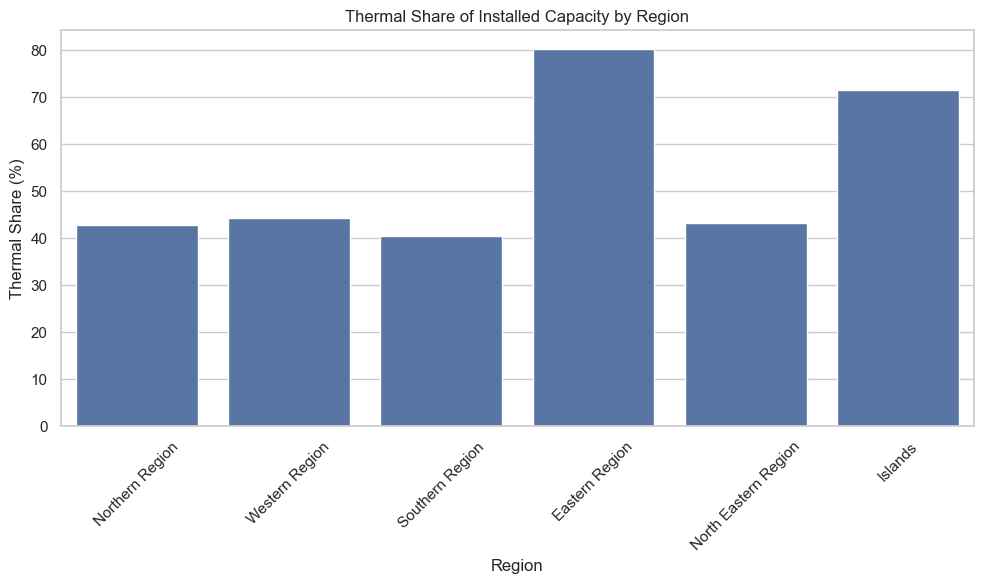

In [28]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=cea_region_total,
    x="Region",
    y="thermal_share_pct"
)
plt.title("Thermal Share of Installed Capacity by Region")
plt.xlabel("Region")
plt.ylabel("Thermal Share (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Regional Generation EDA

## 13. Daily regional generation

The generation dataset covers daily observations from 2017-09-01 to 2020-08-01.

We examine:
- actual generation
- estimated generation
- actual minus estimated
- regional differences
- monthly trends
- variability


In [29]:
generation_daily["Date"] = pd.to_datetime(generation_daily["Date"])

print("Date range:", generation_daily["Date"].min(), "to", generation_daily["Date"].max())
print("Number of dates:", generation_daily["Date"].nunique())
print("Regions:", generation_daily["Region"].unique())

display(generation_daily.head())


Date range: 2017-09-01 00:00:00 to 2020-08-01 00:00:00
Number of dates: 989
Regions: <StringArray>
['Northern', 'Western', 'Southern', 'Eastern', 'NorthEastern']
Length: 5, dtype: str


,Date,Region,Thermal Generation Actual (in MU),Thermal Generation Estimated (in MU),Nuclear Generation Actual (in MU),Nuclear Generation Estimated (in MU),Hydro Generation Actual (in MU),Hydro Generation Estimated (in MU)
0,2017-09-01,Northern,624.230,484.210,30.360,35.570,273.270,320.810
1,2017-09-01,Western,"1,106.890","1,024.330",25.170,3.810,72.000,21.530
2,2017-09-01,Southern,576.660,578.550,62.730,49.800,111.570,64.780
3,2017-09-01,Eastern,441.020,429.390,NaN,NaN,85.940,69.360
4,2017-09-01,NorthEastern,29.110,15.910,NaN,NaN,24.640,21.210


In [30]:
gen_actual_cols = [
    "Thermal Generation Actual (in MU)",
    "Nuclear Generation Actual (in MU)",
    "Hydro Generation Actual (in MU)"
]

gen_est_cols = [
    "Thermal Generation Estimated (in MU)",
    "Nuclear Generation Estimated (in MU)",
    "Hydro Generation Estimated (in MU)"
]

generation_daily["thermal_error_mu"] = (
    generation_daily["Thermal Generation Actual (in MU)"]
    - generation_daily["Thermal Generation Estimated (in MU)"]
)

generation_daily["hydro_error_mu"] = (
    generation_daily["Hydro Generation Actual (in MU)"]
    - generation_daily["Hydro Generation Estimated (in MU)"]
)

generation_daily["nuclear_error_mu"] = (
    generation_daily["Nuclear Generation Actual (in MU)"]
    - generation_daily["Nuclear Generation Estimated (in MU)"]
)

generation_daily["month"] = generation_daily["Date"].dt.to_period("M").astype(str)

display(
    generation_daily.groupby("Region")[gen_actual_cols].agg(["mean", "std"])
)


Thermal Generation Actual (in MU)         \
                                          mean    std   
Region                                                  
Eastern                                487.486 28.291   
NorthEastern                            32.473  2.652   
Northern                               662.334 39.296   
Southern                               617.547 41.681   
Western                              1,220.052 89.116   

             Nuclear Generation Actual (in MU)         \
                                          mean    std   
Region                                                  
Eastern                                    NaN    NaN   
NorthEastern                               NaN    NaN   
Northern                                27.264  3.109   
Southern                                56.476 10.550   
Western                                 27.986  8.983   

             Hydro Generation Actual (in MU)         
                                        mean    std  
Region                                               
Eastern                               49.228 23.207  
NorthEastern                          17.808  8.391  
Northern                             190.955 88.972  
Southern                              71.900 15.588  
Western                               36.638 11.219

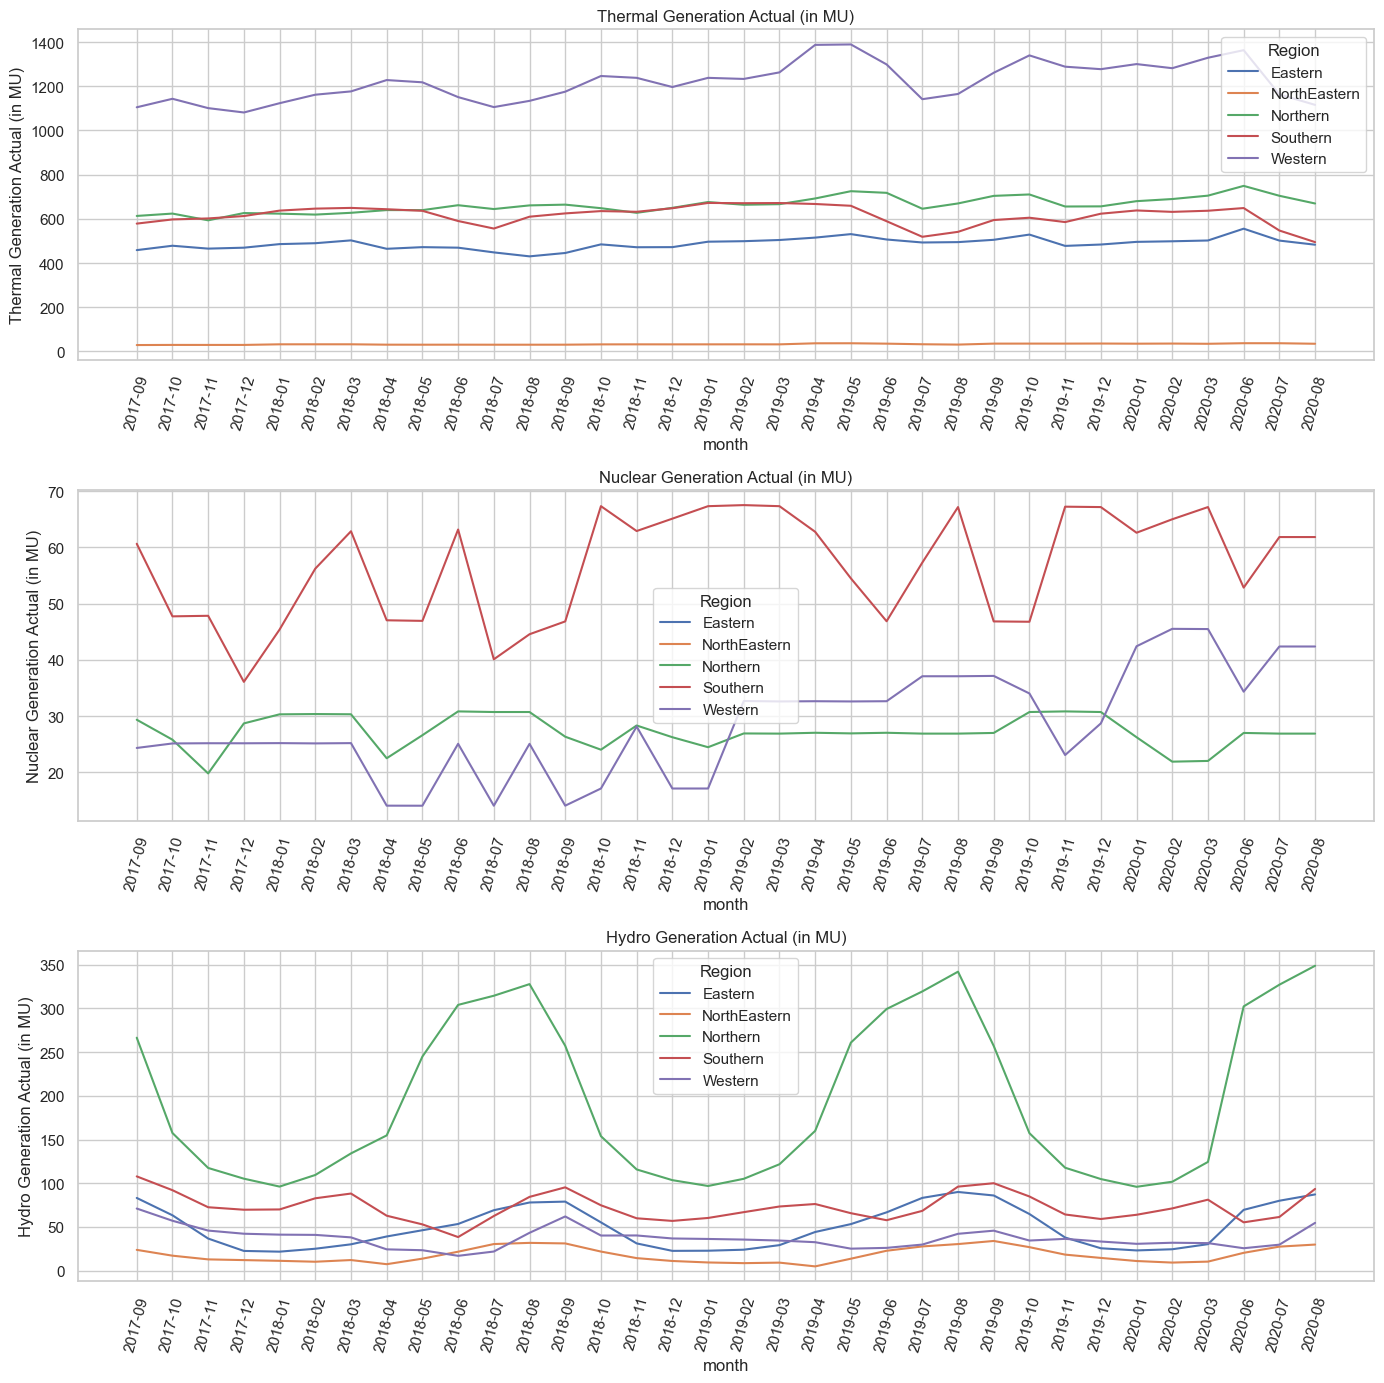

In [31]:
monthly_generation = (
    generation_daily
    .groupby(["month", "Region"], as_index=False)[gen_actual_cols]
    .mean()
)

fig, axes = plt.subplots(3, 1, figsize=(14, 14))

for ax, col in zip(axes, gen_actual_cols):
    sns.lineplot(
        data=monthly_generation,
        x="month",
        y=col,
        hue="Region",
        ax=ax
    )
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=75)

plt.tight_layout()
plt.show()


In [32]:
generation_error_summary = (
    generation_daily
    .groupby("Region")[
        ["thermal_error_mu", "hydro_error_mu", "nuclear_error_mu"]
    ]
    .mean()
    .sort_index()
)

display(generation_error_summary)


,thermal_error_mu,hydro_error_mu,nuclear_error_mu
Region,,,
Eastern,13.440,-3.817,NaN
NorthEastern,-1.001,3.593,NaN
Northern,53.468,-12.487,-4.464
Southern,67.669,-6.041,9.476
Western,9.340,1.067,-4.249


,Region,thermal_generation_mean_mu,thermal_generation_std_mu,hydro_generation_mean_mu,hydro_generation_std_mu,nuclear_generation_mean_mu,nuclear_generation_std_mu,thermal_estimated_diff_mean_mu,hydro_estimated_diff_mean_mu,nuclear_estimated_diff_mean_mu,days_available,thermal_generation_trend_mu_per_day,hydro_generation_trend_mu_per_day,nuclear_generation_trend_mu_per_day
0,Eastern,487.486,28.291,49.228,23.207,NaN,NaN,13.440,-3.817,NaN,989,0.052,0.011,NaN
1,NorthEastern,32.473,2.652,17.808,8.391,NaN,NaN,-1.001,3.593,NaN,989,0.007,0.005,NaN
2,Northern,662.334,39.296,190.955,88.972,27.264,3.109,53.468,-12.487,-4.464,989,0.098,0.047,-0.001
3,Southern,617.547,41.681,71.900,15.588,56.476,10.550,67.669,-6.041,9.476,989,-0.013,-0.011,0.013
4,Western,"1,220.052",89.116,36.638,11.219,27.986,8.983,9.340,1.067,-4.249,989,0.192,-0.016,0.021


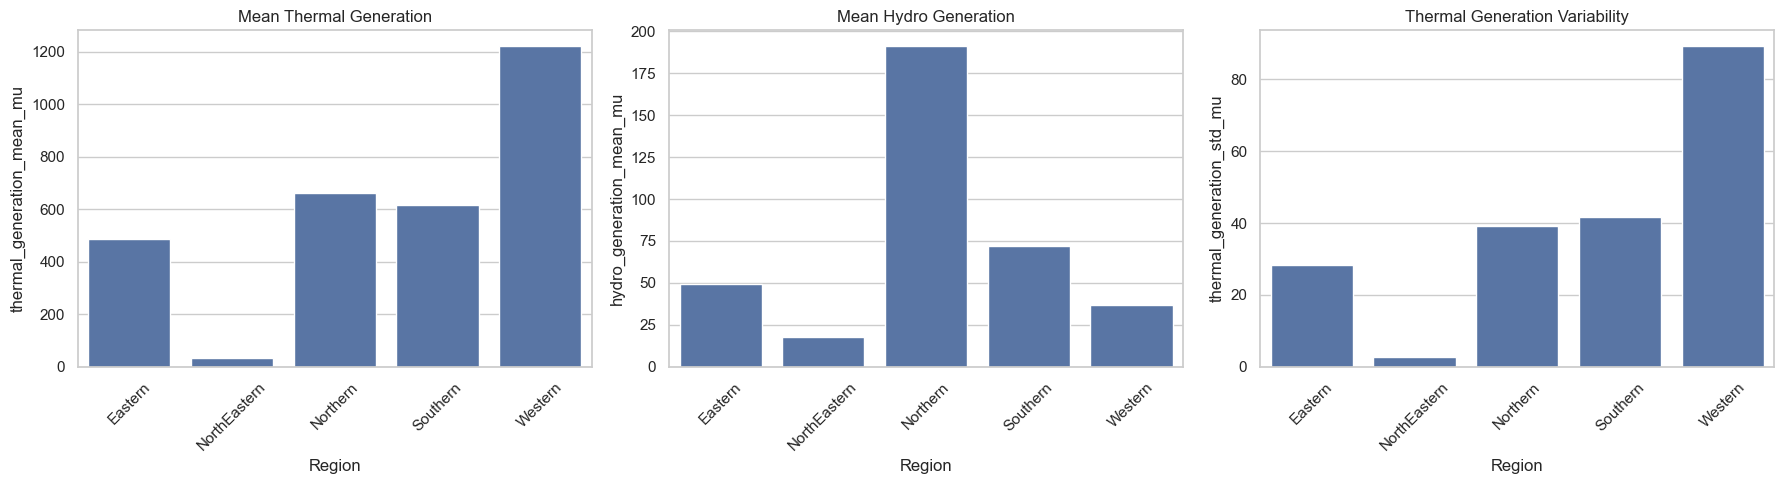

In [33]:
display(generation_features)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(
    data=generation_features,
    x="Region",
    y="thermal_generation_mean_mu",
    ax=axes[0]
)
axes[0].set_title("Mean Thermal Generation")
axes[0].tick_params(axis="x", rotation=45)

sns.barplot(
    data=generation_features,
    x="Region",
    y="hydro_generation_mean_mu",
    ax=axes[1]
)
axes[1].set_title("Mean Hydro Generation")
axes[1].tick_params(axis="x", rotation=45)

sns.barplot(
    data=generation_features,
    x="Region",
    y="thermal_generation_std_mu",
    ax=axes[2]
)
axes[2].set_title("Thermal Generation Variability")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


# Groundwater EDA

## 14. Groundwater data overview

The groundwater dataset is at **district level**, with multi-period summary statistics and trends.

Important:
- Do not collapse directly to one national average.
- Inspect district distributions first.
- State-level summaries are created separately.
- The exact unit/meaning of the groundwater numeric values should be retained from the source metadata; this notebook does not invent a unit.


In [34]:
display(groundwater.head())
print("Rows:", len(groundwater))
print("States:", groundwater["State_Standard"].nunique())
print("Districts:", groundwater["District_Standard"].nunique())

display(
    groundwater[
        [
            "GW_1994_2025_Mean",
            "GW_1994_2025_Median",
            "GW_1994_2025_Std",
            "GW_1994_2025_Trend",
            "GW_2015_2025_Trend",
            "GW_2021_2025_Trend",
            "GW_Latest_2025",
            "GW_Recent_vs_Early_Change"
        ]
    ].describe().T
)


,State_Standard,District_Standard,GW_1994_2025_Mean,GW_1994_2025_Median,GW_1994_2025_Std,GW_1994_2025_Trend,GW_1994_2025_Years_Available,GW_2015_2025_Mean,GW_2015_2025_Median,GW_2015_2025_Std,GW_2015_2025_Trend,GW_2015_2025_Years_Available,GW_2021_2025_Mean,GW_2021_2025_Median,GW_2021_2025_Std,GW_2021_2025_Trend,GW_2021_2025_Years_Available,GW_Latest_2025,GW_Latest_Median_2025,GW_Latest_Std_2025,GW_Stations_2025,GW_Mean_2015_2019,GW_Mean_2021_2025,GW_Recent_vs_Early_Change,GW_2025_Available,GW_2015_2025_Coverage_Ratio,GW_2021_2025_Coverage_Ratio
0,Andaman And Nicobar Islands,North And Middle Andaman,1.937,1.756,0.789,-0.019,23,1.833,1.647,0.810,-0.028,9.000,1.846,1.741,0.973,0.157,4.000,1.187,0.965,0.880,38.000,1.822,1.846,0.024,1,0.818,0.800
1,Andaman And Nicobar Islands,South Andamans,2.151,1.873,0.677,-0.013,24,2.106,1.820,0.551,-0.022,9.000,2.124,1.843,0.558,-0.010,4.000,1.580,1.270,1.277,71.000,2.092,2.124,0.032,1,0.818,0.800
2,Andhra Pradesh,Alluri Sitharama Raju,6.194,5.832,1.073,-0.079,30,5.241,4.718,0.845,-0.114,9.000,4.818,4.280,1.188,-0.498,4.000,3.158,2.970,2.080,33.000,5.579,4.818,-0.761,1,0.818,0.800
3,Andhra Pradesh,Anakapalli,4.736,4.386,0.929,-0.040,30,4.204,3.679,0.813,0.002,9.000,4.004,3.500,0.974,0.200,4.000,3.460,3.200,1.916,24.000,4.364,4.004,-0.361,1,0.818,0.800
4,Andhra Pradesh,Ananthapuramu,8.553,7.605,2.533,-0.055,31,7.906,6.614,2.476,0.242,10.000,8.749,5.631,3.555,2.094,4.000,9.964,6.275,10.370,26.000,7.693,8.749,1.057,1,0.909,0.800


Rows: 717
States: 33
Districts: 714


,count,mean,std,min,25%,50%,75%,max
GW_1994_2025_Mean,717.000,8.729,6.251,0.735,5.454,7.544,9.636,57.000
GW_1994_2025_Median,717.000,8.052,5.993,0.632,4.975,6.918,8.912,56.407
GW_1994_2025_Std,713.000,1.988,2.081,0.227,0.850,1.346,2.218,21.373
GW_1994_2025_Trend,713.000,0.099,1.049,-6.886,-0.048,-0.006,0.037,21.285
GW_2015_2025_Trend,708.000,0.025,1.121,-6.886,-0.211,-0.075,0.036,21.285
GW_2021_2025_Trend,707.000,0.158,1.430,-12.821,-0.189,0.070,0.414,21.285
GW_Latest_2025,698.000,8.764,8.473,0.935,4.499,6.391,9.091,76.084
GW_Recent_vs_Early_Change,686.000,-0.486,2.737,-9.976,-1.635,-0.661,0.095,43.475


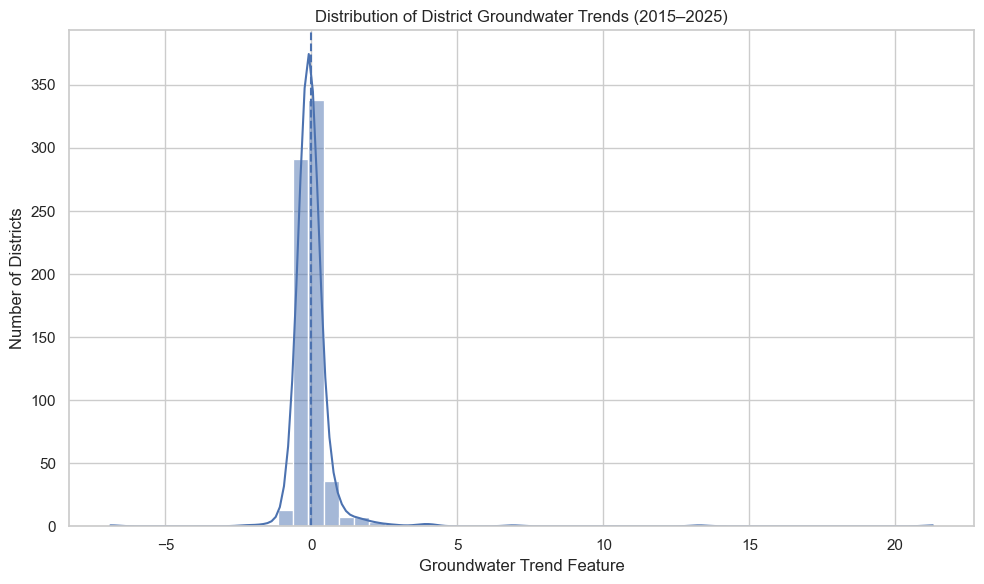

In [35]:
plt.figure(figsize=(10, 6))
sns.histplot(
    groundwater["GW_2015_2025_Trend"].dropna(),
    kde=True
)
plt.axvline(0, linestyle="--")
plt.title("Distribution of District Groundwater Trends (2015–2025)")
plt.xlabel("Groundwater Trend Feature")
plt.ylabel("Number of Districts")
plt.tight_layout()
plt.show()


In [36]:
state_gw = (
    groundwater
    .groupby("State_Standard")
    .agg(
        districts=("District_Standard", "nunique"),
        median_2015_2025=("GW_2015_2025_Median", "median"),
        median_2021_2025=("GW_2021_2025_Median", "median"),
        median_2021_2025_trend=("GW_2021_2025_Trend", "median"),
        median_recent_change=("GW_Recent_vs_Early_Change", "median"),
        stations_2025=("GW_Stations_2025", "sum"),
        coverage_2015_2025=("GW_2015_2025_Coverage_Ratio", "mean")
    )
    .reset_index()
)

display(state_gw.sort_values("median_2021_2025_trend").head(15))


,State_Standard,districts,median_2015_2025,median_2021_2025,median_2021_2025_trend,median_recent_change,stations_2025,coverage_2015_2025
11,Haryana,22,11.342,11.318,-0.479,0.447,234.000,0.967
18,Maharashtra,36,7.575,6.550,-0.359,-1.977,"1,788.000",0.856
10,Gujarat,33,8.602,7.808,-0.307,-1.647,746.000,1.000
9,Goa,2,5.014,5.443,-0.237,0.508,73.000,0.818
8,Delhi,12,10.658,9.311,-0.156,-0.668,123.000,0.947
19,Manipur,3,2.799,2.799,-0.152,NaN,4.000,0.182
20,Meghalaya,11,3.234,2.979,-0.132,-0.324,71.000,0.864
17,Madhya Pradesh,55,8.523,8.023,-0.110,-1.115,"1,082.000",1.000
27,Tamil Nadu,38,6.146,4.451,-0.064,-2.485,831.000,0.888
23,Odisha,30,4.915,4.742,-0.052,-0.268,"1,290.000",0.991


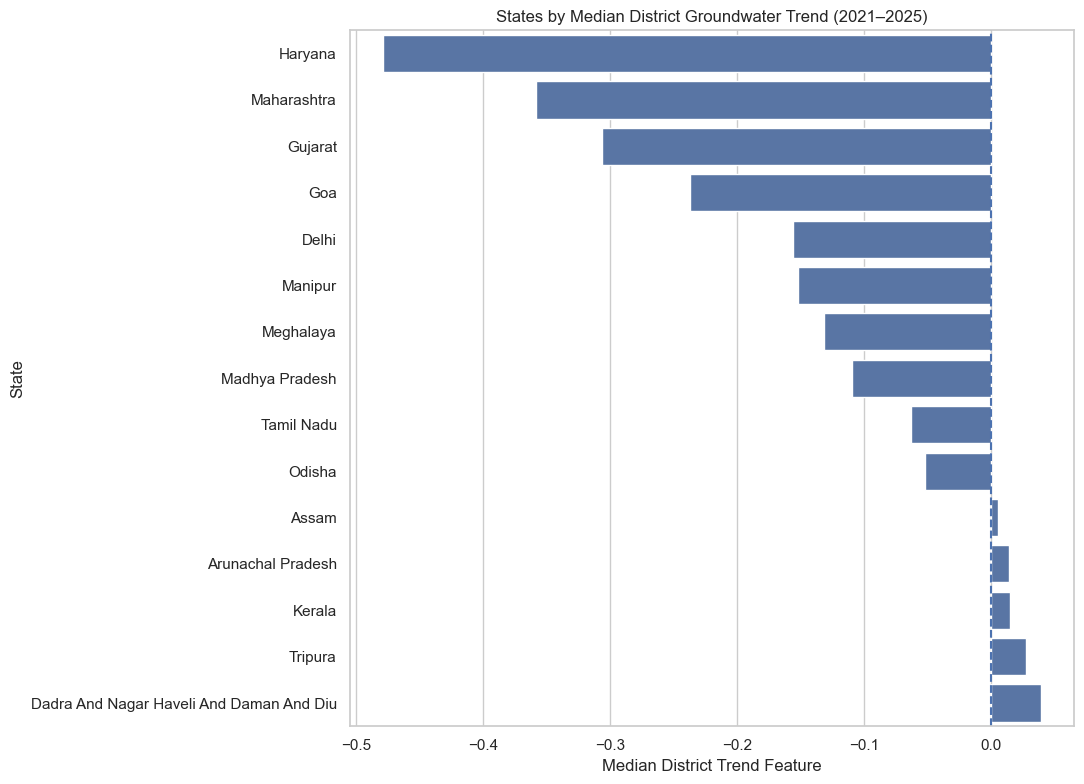

In [37]:
gw_trend_top = state_gw.sort_values(
    "median_2021_2025_trend"
).head(15)

plt.figure(figsize=(11, 8))
sns.barplot(
    data=gw_trend_top,
    y="State_Standard",
    x="median_2021_2025_trend"
)
plt.axvline(0, linestyle="--")
plt.title("States by Median District Groundwater Trend (2021–2025)")
plt.xlabel("Median District Trend Feature")
plt.ylabel("State")
plt.tight_layout()
plt.show()


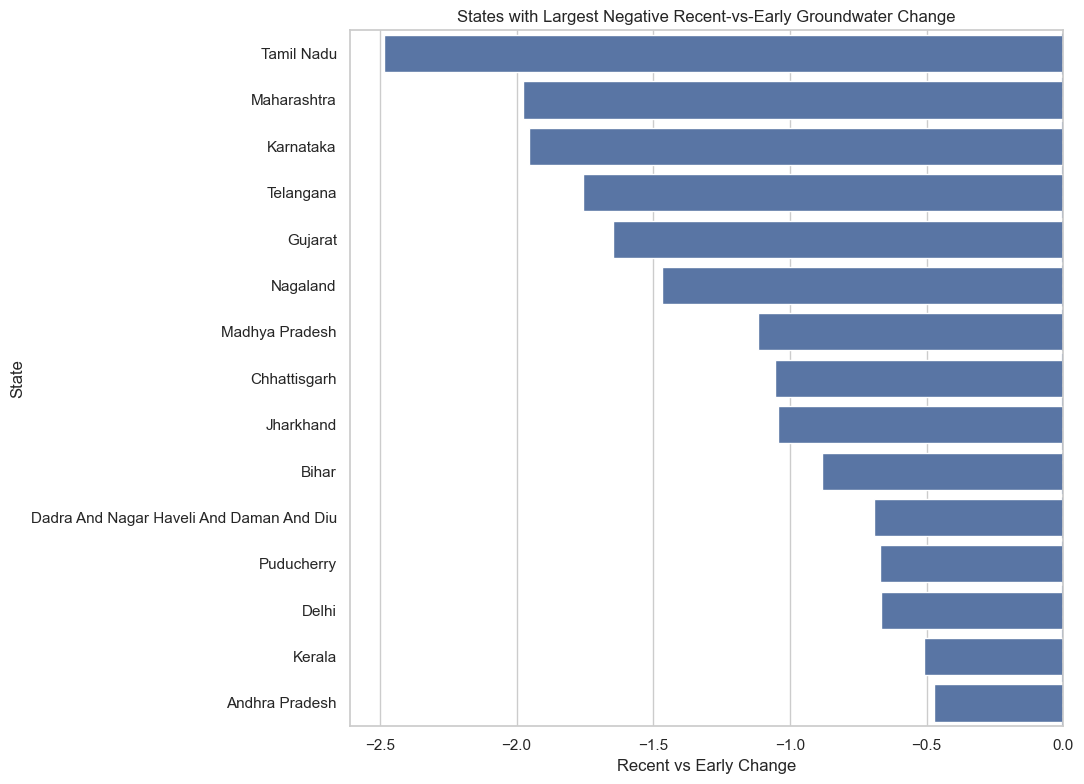

In [38]:
gw_change = state_gw.sort_values(
    "median_recent_change"
)

plt.figure(figsize=(11, 8))
sns.barplot(
    data=gw_change.head(15),
    y="State_Standard",
    x="median_recent_change"
)
plt.axvline(0, linestyle="--")
plt.title("States with Largest Negative Recent-vs-Early Groundwater Change")
plt.xlabel("Recent vs Early Change")
plt.ylabel("State")
plt.tight_layout()
plt.show()


# Water-body EDA

## 15. Water-body distribution

Water-body counts are indicators of the recorded water-body distribution. They are **not equivalent to water volume, groundwater availability, or usable industrial water**.

In [39]:
display(waterbodies.head())

water_size_cols = [
    "waterbody_count_lt_0_5ha",
    "waterbody_count_0_5_1ha",
    "waterbody_count_1_2ha",
    "waterbody_count_2_10ha",
    "waterbody_count_10_50ha",
    "waterbody_count_50_100ha",
    "waterbody_count_gte_100ha"
]

display(
    waterbodies[
        ["state_name", "waterbody_count_total"]
        + water_size_cols
    ].sort_values("waterbody_count_total", ascending=False).head(15)
)


,state_id,state_name,waterbody_count_total,waterbody_count_lt_0_5ha,waterbody_count_0_5_1ha,waterbody_count_1_2ha,waterbody_count_2_10ha,waterbody_count_10_50ha,waterbody_count_50_100ha,waterbody_count_gte_100ha
0,IN-AN,Andaman and Nicobar Islands,33,9,1,2,9,4,6,2
1,IN-AP,Andhra Pradesh,36733,3342,5265,7203,14535,5057,783,548
2,IN-AR,Arunachal Pradesh,1275,187,150,222,488,214,13,1
3,IN-AS,Assam,14636,8796,2209,1416,1574,539,63,39
4,IN-BR,Bihar,61370,36455,13572,6268,3964,929,110,72


,state_name,waterbody_count_total,waterbody_count_lt_0_5ha,waterbody_count_0_5_1ha,waterbody_count_1_2ha,waterbody_count_2_10ha,waterbody_count_10_50ha,waterbody_count_50_100ha,waterbody_count_gte_100ha
6,Chhattisgarh,104447,50490,25155,17755,9669,1183,102,93
35,West Bengal,104357,61523,27474,8981,4683,1410,179,107
25,Odisha,90888,55485,19699,9451,5529,538,75,111
28,Rajasthan,82075,42022,11439,11839,12749,3328,404,294
30,Tamil Nadu,73575,25785,11458,7302,14167,12054,1941,868
19,Madhya Pradesh,65940,24428,17099,11963,9482,2266,366,336
4,Bihar,61370,36455,13572,6268,3964,929,110,72
15,Karnataka,53378,23845,7619,6172,10167,4440,695,440
20,Maharashtra,40106,11864,6382,6300,11177,3212,591,580
14,Jharkhand,38912,23533,8834,4118,2166,187,25,49


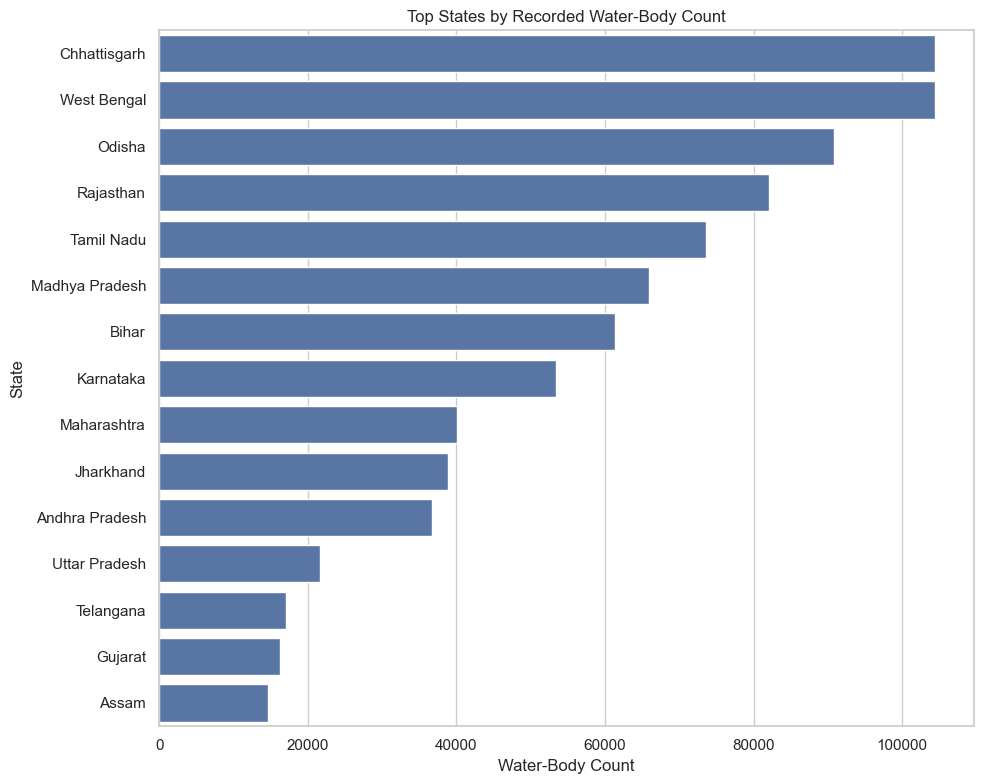

In [40]:
water_top = waterbodies.sort_values(
    "waterbody_count_total", ascending=False
).head(15)

plt.figure(figsize=(10, 8))
sns.barplot(
    data=water_top,
    y="state_name",
    x="waterbody_count_total"
)
plt.title("Top States by Recorded Water-Body Count")
plt.xlabel("Water-Body Count")
plt.ylabel("State")
plt.tight_layout()
plt.show()


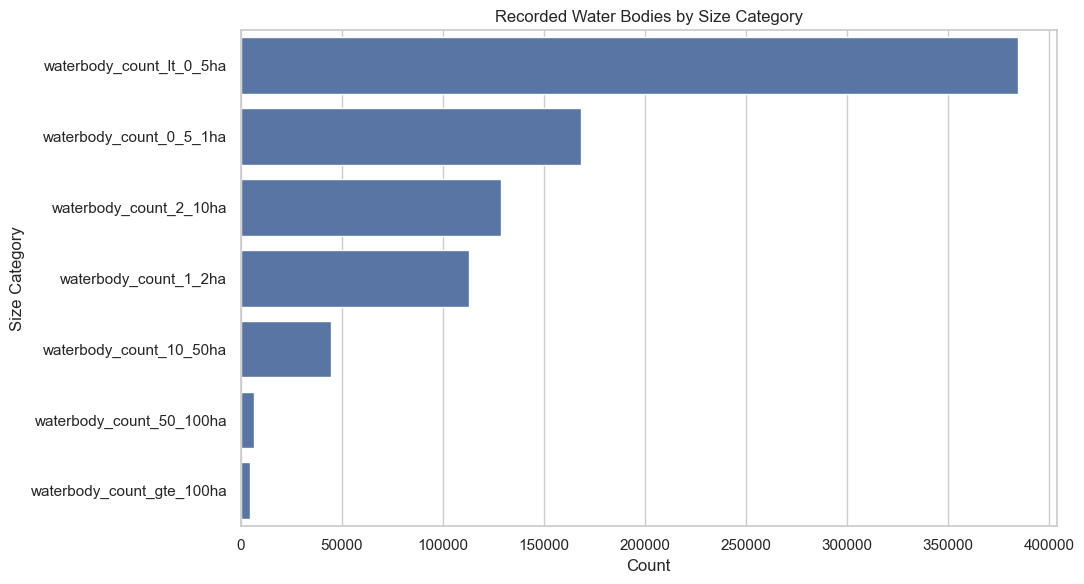

In [41]:
water_size_totals = waterbodies[water_size_cols].sum().sort_values(ascending=False)

plt.figure(figsize=(11, 6))
sns.barplot(
    x=water_size_totals.values,
    y=water_size_totals.index
)
plt.title("Recorded Water Bodies by Size Category")
plt.xlabel("Count")
plt.ylabel("Size Category")
plt.tight_layout()
plt.show()


In [42]:
water_density = waterbodies.merge(
    states[["state_id", "area_km2"]],
    on="state_id",
    how="left"
)

water_density["waterbody_density_per_1000km2"] = (
    water_density["waterbody_count_total"]
    / water_density["area_km2"]
    * 1000
)

display(
    water_density[
        ["state_name", "area_km2", "waterbody_count_total",
         "waterbody_density_per_1000km2"]
    ].sort_values(
        "waterbody_density_per_1000km2",
        ascending=False
    ).head(15)
)


,state_name,area_km2,waterbody_count_total,waterbody_density_per_1000km2
35,West Bengal,"88,752.000",104357,"1,175.827"
6,Chhattisgarh,"135,191.000",104447,772.588
4,Bihar,"94,163.000",61370,651.742
25,Odisha,"155,707.000",90888,583.712
30,Tamil Nadu,"130,058.000",73575,565.709
14,Jharkhand,"79,714.000",38912,488.145
16,Kerala,"38,863.000",11460,294.882
15,Karnataka,"191,791.000",53378,278.313
28,Rajasthan,"342,239.000",82075,239.818
1,Andhra Pradesh,"162,970.000",36733,225.397


# Data-Centre Market EDA

## 16. Data-centre distribution

`fact_market_datacentres` is a market/state snapshot, not a historical time series.

Therefore the EDA focuses on:
- market concentration
- state concentration
- relationship with current resource indicators

It should not be interpreted as a time-series growth analysis.

In [43]:
display(datacentres.sort_values("data_center_count", ascending=False))

dc_state = (
    datacentres
    .groupby(["state_id", "state_name"], as_index=False)["data_center_count"]
    .sum()
    .sort_values("data_center_count", ascending=False)
)

display(dc_state.head(15))


,market,state_id,state_name,data_center_count
0,Mumbai,IN-MH,Maharashtra,60
2,Hyderabad,IN-TG,Telangana,36
1,Chennai,IN-TN,Tamil Nadu,33
4,Bangalore,IN-KA,Karnataka,31
3,Navi Mumbai,IN-MH,Maharashtra,25
5,Noida,IN-UP,Uttar Pradesh,19
6,Pune,IN-MH,Maharashtra,17
7,New Delhi,IN-DL,Delhi,12
8,Ahmedabad,IN-GJ,Gujarat,11
9,Kolkata,IN-WB,West Bengal,8


,state_id,state_name,data_center_count
8,IN-MH,Maharashtra,104
15,IN-TN,Tamil Nadu,37
14,IN-TG,Telangana,36
6,IN-KA,Karnataka,31
17,IN-UP,Uttar Pradesh,21
3,IN-DL,Delhi,12
4,IN-GJ,Gujarat,12
18,IN-WB,West Bengal,9
5,IN-HR,Haryana,8
0,IN-AP,Andhra Pradesh,7


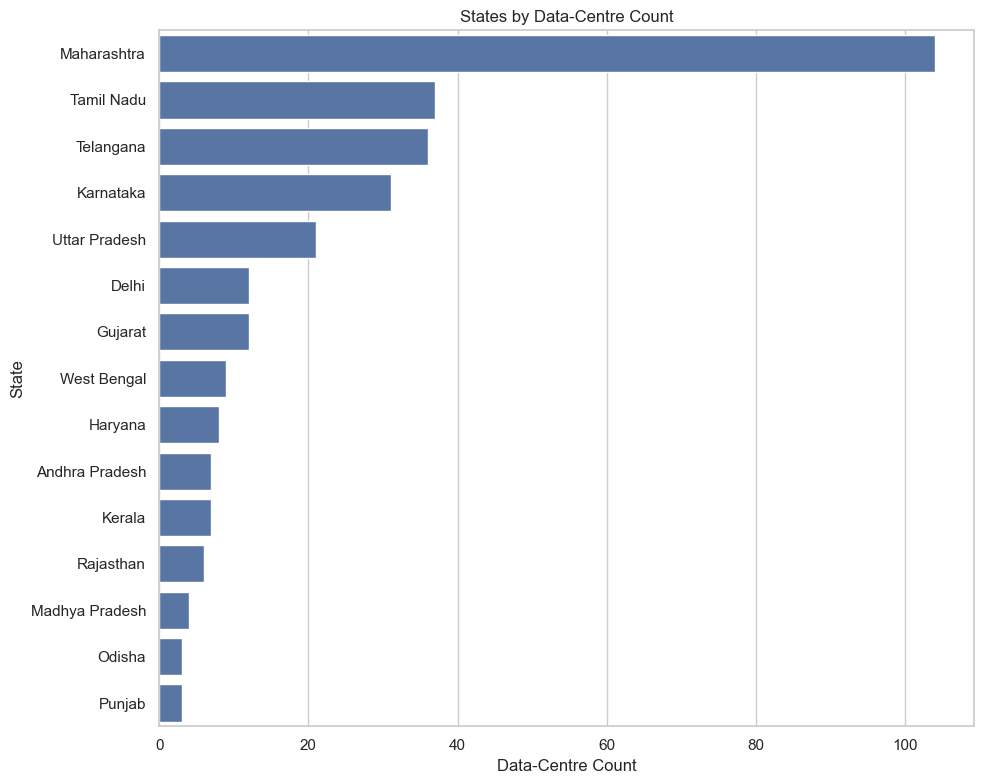

In [44]:
plt.figure(figsize=(10, 8))
sns.barplot(
    data=dc_state.head(15),
    y="state_name",
    x="data_center_count"
)
plt.title("States by Data-Centre Count")
plt.xlabel("Data-Centre Count")
plt.ylabel("State")
plt.tight_layout()
plt.show()


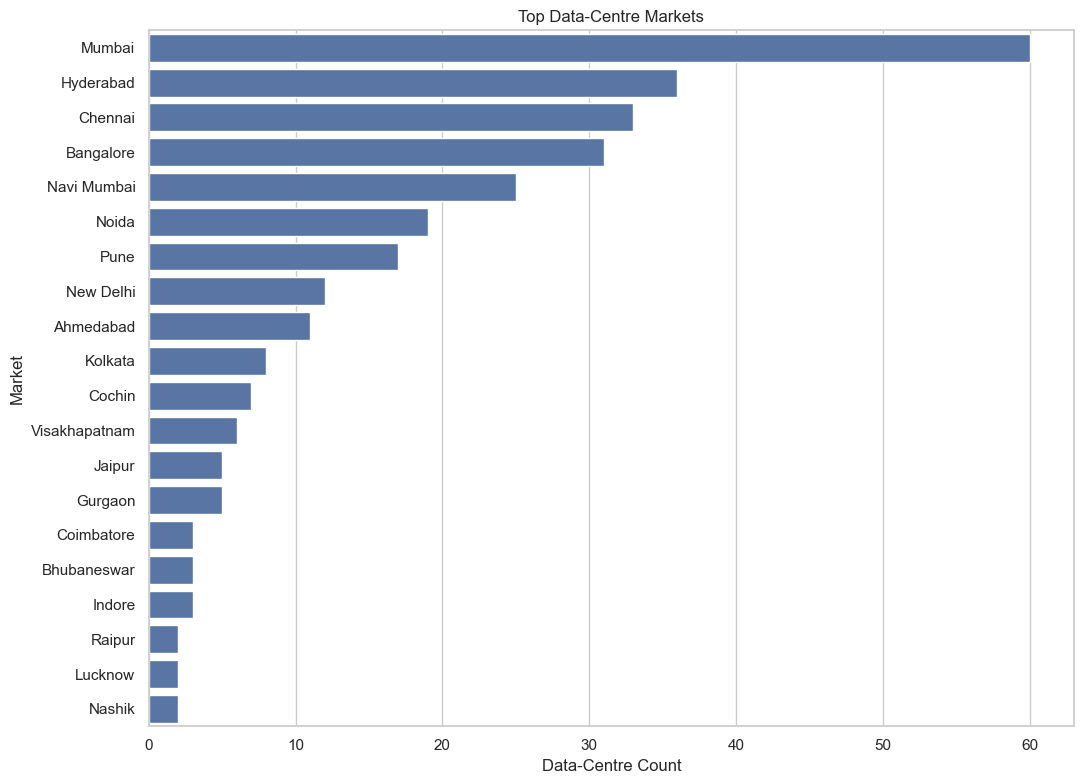

In [45]:
dc_market = datacentres.sort_values(
    "data_center_count", ascending=False
).head(20)

plt.figure(figsize=(11, 8))
sns.barplot(
    data=dc_market,
    y="market",
    x="data_center_count"
)
plt.title("Top Data-Centre Markets")
plt.xlabel("Data-Centre Count")
plt.ylabel("Market")
plt.tight_layout()
plt.show()


# Integrated State-Level EDA

## 17. Build the state-level analytical table

This table brings together the currently available state-level indicators:

- renewable capacity and growth
- renewable potential/headroom/utilization
- water-body indicators
- groundwater summaries
- data-centre counts
- state area and region

This is an **EDA integration table**, not the final ML master panel.

In [46]:
# Normalize groundwater state names using state IDs indirectly through the state-name mapping.
# First create a simple normalized name helper.

def normalize_name(x):
    if pd.isna(x):
        return x
    return (
        str(x).lower()
        .replace("&", "and")
        .replace(".", "")
        .replace("-", " ")
        .replace("  ", " ")
        .strip()
    )

state_lookup = states[["state_id", "state_name", "region", "area_km2"]].copy()
state_lookup["name_key"] = state_lookup["state_name"].map(normalize_name)

# Renewable features
integrated = state_lookup.merge(
    mnre_features,
    on=["state_id", "state_name"],
    how="left",
    suffixes=("", "_mnre")
)

# Water bodies
integrated = integrated.merge(
    waterbodies[
        ["state_id", "waterbody_count_total"] + water_size_cols
    ],
    on="state_id",
    how="left"
)

# Data centres
integrated = integrated.merge(
    dc_state[["state_id", "data_center_count"]],
    on="state_id",
    how="left"
)

# Water-body density
integrated["waterbody_density_per_1000km2"] = (
    integrated["waterbody_count_total"] / integrated["area_km2"] * 1000
)

# Match groundwater using normalized state names.
gw_state_name = (
    groundwater[["State_Standard", "District_Standard",
                 "GW_2015_2025_Median", "GW_2021_2025_Median",
                 "GW_2021_2025_Trend", "GW_Recent_vs_Early_Change",
                 "GW_Stations_2025", "GW_2015_2025_Coverage_Ratio"]]
    .copy()
)

gw_state_name["name_key"] = gw_state_name["State_Standard"].map(normalize_name)

gw_state_agg = (
    gw_state_name
    .groupby("name_key")
    .agg(
        groundwater_districts=("District_Standard", "nunique"),
        groundwater_median_2015_2025=("GW_2015_2025_Median", "median"),
        groundwater_median_2021_2025=("GW_2021_2025_Median", "median"),
        groundwater_median_trend_2021_2025=("GW_2021_2025_Trend", "median"),
        groundwater_recent_change=("GW_Recent_vs_Early_Change", "median"),
        groundwater_stations_2025=("GW_Stations_2025", "sum"),
        groundwater_coverage=("GW_2015_2025_Coverage_Ratio", "mean")
    )
    .reset_index()
)

integrated = integrated.merge(
    gw_state_agg,
    on="name_key",
    how="left"
)

print("Integrated table shape:", integrated.shape)
display(integrated.head())


Integrated table shape: (36, 36)


,state_id,state_name,region,area_km2,name_key,small_hydro_mw,wind_power_mw,bio_power_mw,solar_power_mw,large_hydro_mw,total_re_mw,total_re_potential_mw,renewable_headroom_mw,renewable_utilization_pct,re_capacity_2017_18_mw,re_capacity_2024_25_mw,re_capacity_growth_mw,re_capacity_growth_pct,re_capacity_cagr_pct,waterbody_count_total,waterbody_count_lt_0_5ha,waterbody_count_0_5_1ha,waterbody_count_1_2ha,waterbody_count_2_10ha,waterbody_count_10_50ha,waterbody_count_50_100ha,waterbody_count_gte_100ha,data_center_count,waterbody_density_per_1000km2,groundwater_districts,groundwater_median_2015_2025,groundwater_median_2021_2025,groundwater_median_trend_2021_2025,groundwater_recent_change,groundwater_stations_2025,groundwater_coverage
0,IN-PY,Puducherry,Southern,492.000,puducherry,0.000,0.000,0.000,54.510,0.000,54.510,608.900,554.390,8.952,0.340,54.510,54.170,"15,932.353",106.538,107,18,11,7,31,29,5,6,1.000,217.480,2.000,3.293,3.232,0.100,-0.672,8.000,0.864
1,IN-MH,Maharashtra,Western,"307,713.000",maharashtra,384.280,"5,284.610","2,998.300","10,687.270","3,047.000","22,401.460","671,023.690","648,622.230",3.338,"11,519.210","22,401.460","10,882.250",94.470,9.968,40106,11864,6382,6300,11177,3212,591,580,104.000,130.336,36.000,7.575,6.550,-0.359,-1.977,"1,788.000",0.856
2,IN-NL,Nagaland,Northeastern,"16,579.000",nagaland,32.670,0.000,0.000,3.170,75.000,110.840,752.040,641.200,14.739,108.510,110.840,2.330,2.147,0.304,462,276,102,54,26,3,0,1,NaN,27.867,8.000,5.947,3.935,0.881,-1.466,101.000,0.375
3,IN-LD,Lakshadweep,NaN,NaN,lakshadweep,0.000,0.000,0.000,4.970,0.000,4.970,32.390,27.420,15.344,3.140,4.970,1.830,58.280,6.780,2,1,1,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,IN-UP,Uttar Pradesh,Northern,"240,928.000",uttar pradesh,49.100,0.000,"2,309.140","3,364.070",501.600,"6,223.910","107,041.350","100,817.440",5.814,"3,447.250","6,223.910","2,776.660",80.547,8.807,21574,1394,4577,5164,7104,2734,367,234,21.000,89.545,75.000,6.676,6.541,0.288,-0.211,990.000,0.921


## 18. Integrated correlation analysis

Use Spearman correlation because several resource variables can be skewed and relationships may not be linear.

Again, this is **association analysis only**.

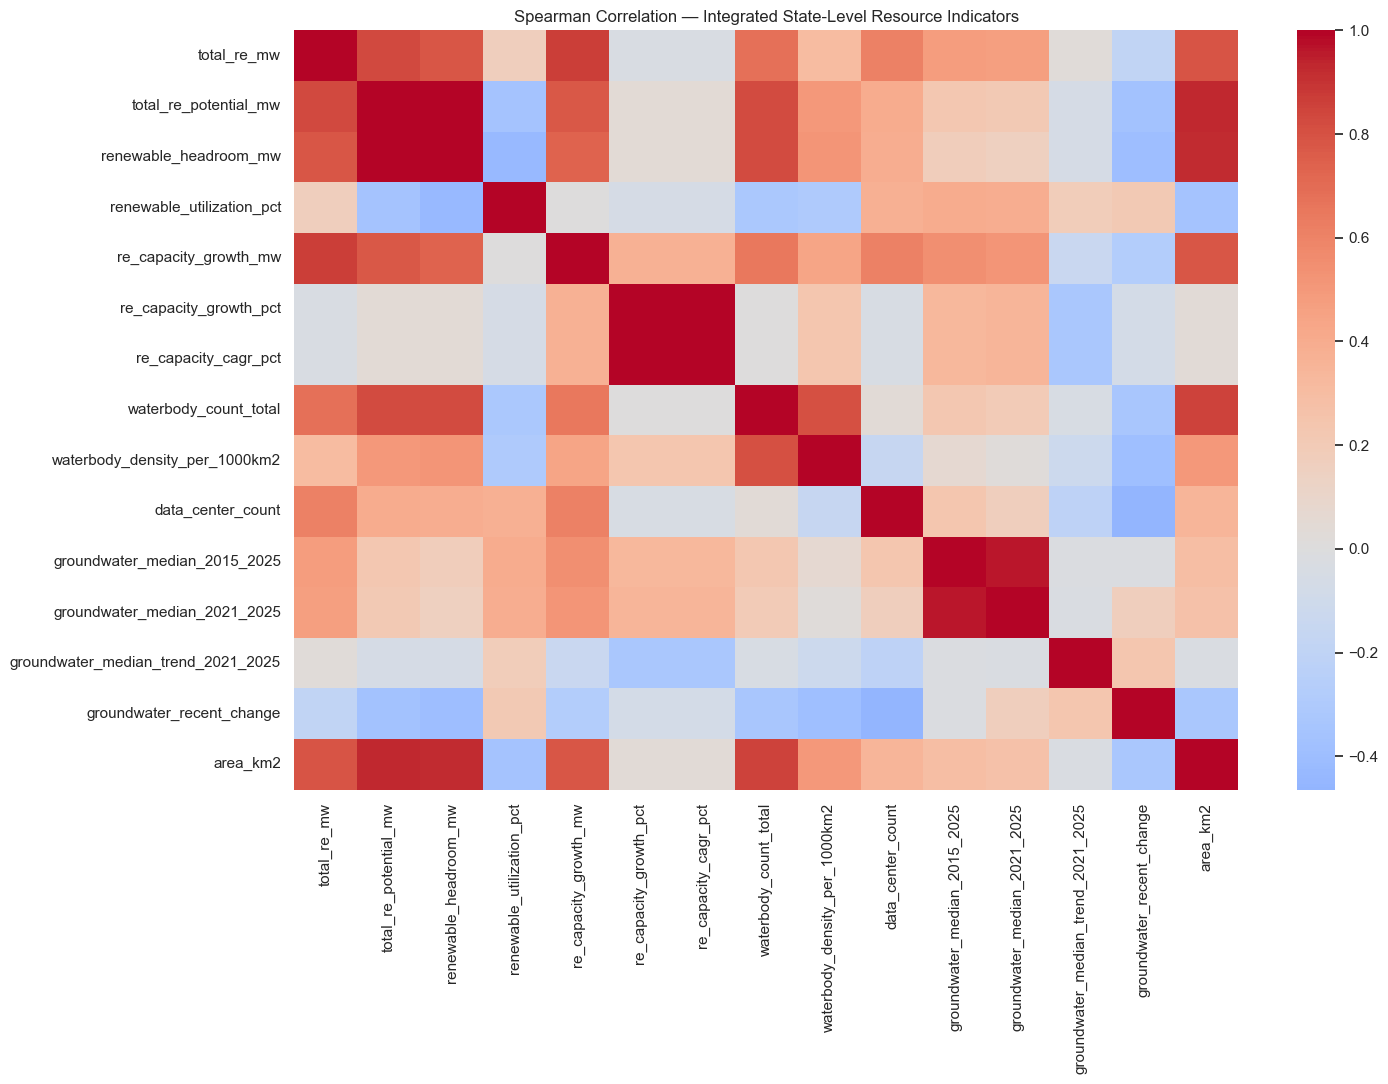

In [47]:
corr_cols = [
    "total_re_mw",
    "total_re_potential_mw",
    "renewable_headroom_mw",
    "renewable_utilization_pct",
    "re_capacity_growth_mw",
    "re_capacity_growth_pct",
    "re_capacity_cagr_pct",
    "waterbody_count_total",
    "waterbody_density_per_1000km2",
    "data_center_count",
    "groundwater_median_2015_2025",
    "groundwater_median_2021_2025",
    "groundwater_median_trend_2021_2025",
    "groundwater_recent_change",
    "area_km2"
]

available_corr_cols = [c for c in corr_cols if c in integrated.columns]

corr = integrated[available_corr_cols].corr(method="spearman")

plt.figure(figsize=(15, 11))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    annot=False
)
plt.title("Spearman Correlation — Integrated State-Level Resource Indicators")
plt.tight_layout()
plt.show()


## 19. Data-centre count vs renewable resources

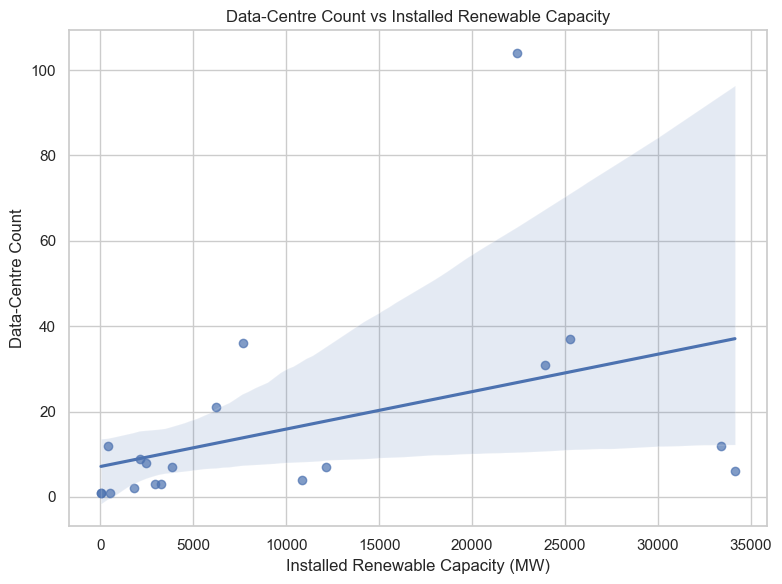

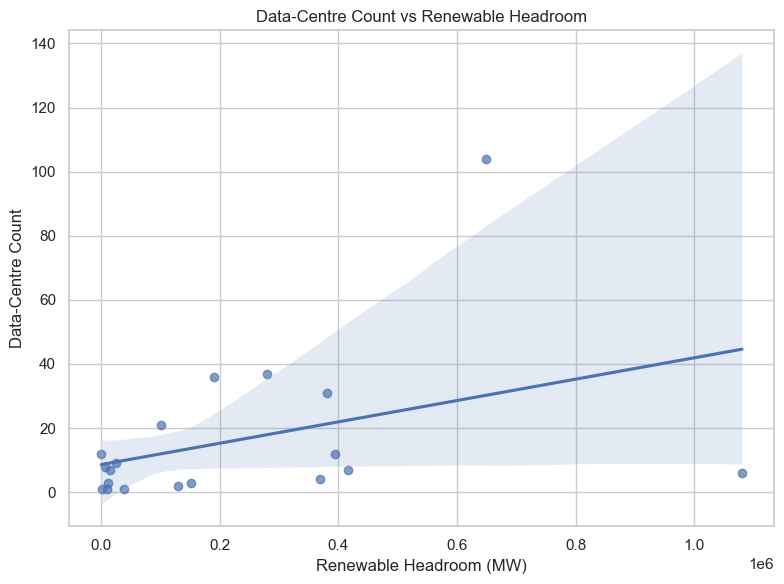

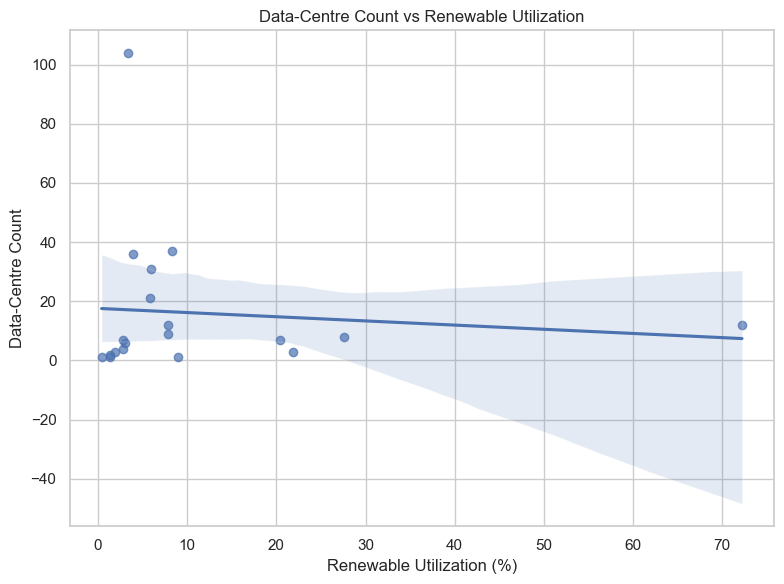

In [48]:
def scatter_if_available(x, y, title, xlabel, ylabel):
    if x in integrated.columns and y in integrated.columns:
        d = integrated[[x, y]].dropna()
        if len(d) >= 3:
            plt.figure(figsize=(8, 6))
            sns.regplot(
                data=d,
                x=x,
                y=y,
                scatter_kws={"alpha": 0.7}
            )
            plt.title(title)
            plt.xlabel(xlabel)
            plt.ylabel(ylabel)
            plt.tight_layout()
            plt.show()

scatter_if_available(
    "total_re_mw",
    "data_center_count",
    "Data-Centre Count vs Installed Renewable Capacity",
    "Installed Renewable Capacity (MW)",
    "Data-Centre Count"
)

scatter_if_available(
    "renewable_headroom_mw",
    "data_center_count",
    "Data-Centre Count vs Renewable Headroom",
    "Renewable Headroom (MW)",
    "Data-Centre Count"
)

scatter_if_available(
    "renewable_utilization_pct",
    "data_center_count",
    "Data-Centre Count vs Renewable Utilization",
    "Renewable Utilization (%)",
    "Data-Centre Count"
)


## 20. Data-centre count vs water and groundwater indicators

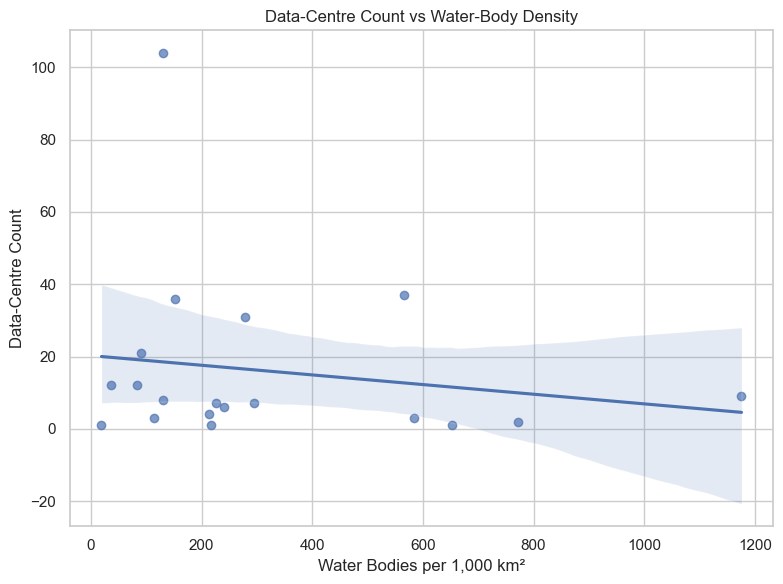

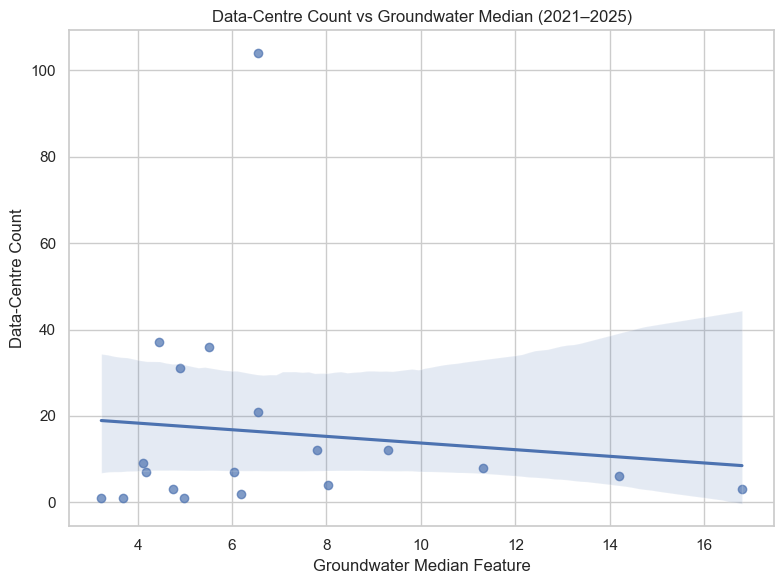

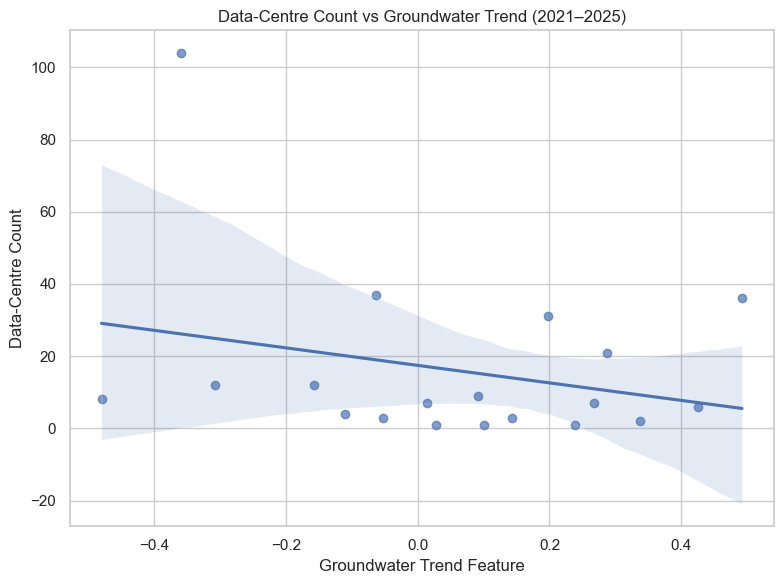

In [49]:
scatter_if_available(
    "waterbody_density_per_1000km2",
    "data_center_count",
    "Data-Centre Count vs Water-Body Density",
    "Water Bodies per 1,000 km²",
    "Data-Centre Count"
)

scatter_if_available(
    "groundwater_median_2021_2025",
    "data_center_count",
    "Data-Centre Count vs Groundwater Median (2021–2025)",
    "Groundwater Median Feature",
    "Data-Centre Count"
)

scatter_if_available(
    "groundwater_median_trend_2021_2025",
    "data_center_count",
    "Data-Centre Count vs Groundwater Trend (2021–2025)",
    "Groundwater Trend Feature",
    "Data-Centre Count"
)


# Optional Maps

## 21. State maps using the supplied GeoJSON

The maps are optional. If `geopandas` is unavailable, the notebook will skip them without affecting the rest of the EDA.

In [50]:
try:
    import geopandas as gpd

    geo_path = DATA_DIR / FILES["geojson"]
    gdf = gpd.read_file(geo_path)

    print("GeoJSON loaded:", gdf.shape)
    display(gdf.head())
except Exception as e:
    gdf = None
    print("GeoJSON map section skipped:", e)


GeoJSON loaded: (36, 8)


,state_id,state_name,shapeISO,shapeID,area_km2,region,national_share_pct,geometry
0,IN-PY,Puducherry,IN-PY,1811400B81659894240990,492.000,Southern,0.010,"MULTIPOLYGON (((75.53056 11.70403, 75.53015 11..."
1,IN-MH,Maharashtra,IN-MH,1811400B15614733245507,"307,713.000",Western,9.360,"MULTIPOLYGON (((80.27289 18.72299, 80.27266 18..."
2,IN-NL,Nagaland,IN-NL,1811400B74762431478096,"16,579.000",Northeastern,0.500,"POLYGON ((95.23392 26.68246, 95.23339 26.68291..."
3,IN-LD,Lakshadweep,IN-LD,1811400B55669546485086,NaN,NaN,NaN,"MULTIPOLYGON (((73.01113 8.27759, 73.01103 8.2..."
4,IN-UP,Uttar Pradesh,IN-UP,1811400B11231190780494,"240,928.000",Northern,7.330,"MULTIPOLYGON (((79.39526 25.03209, 79.39598 25..."


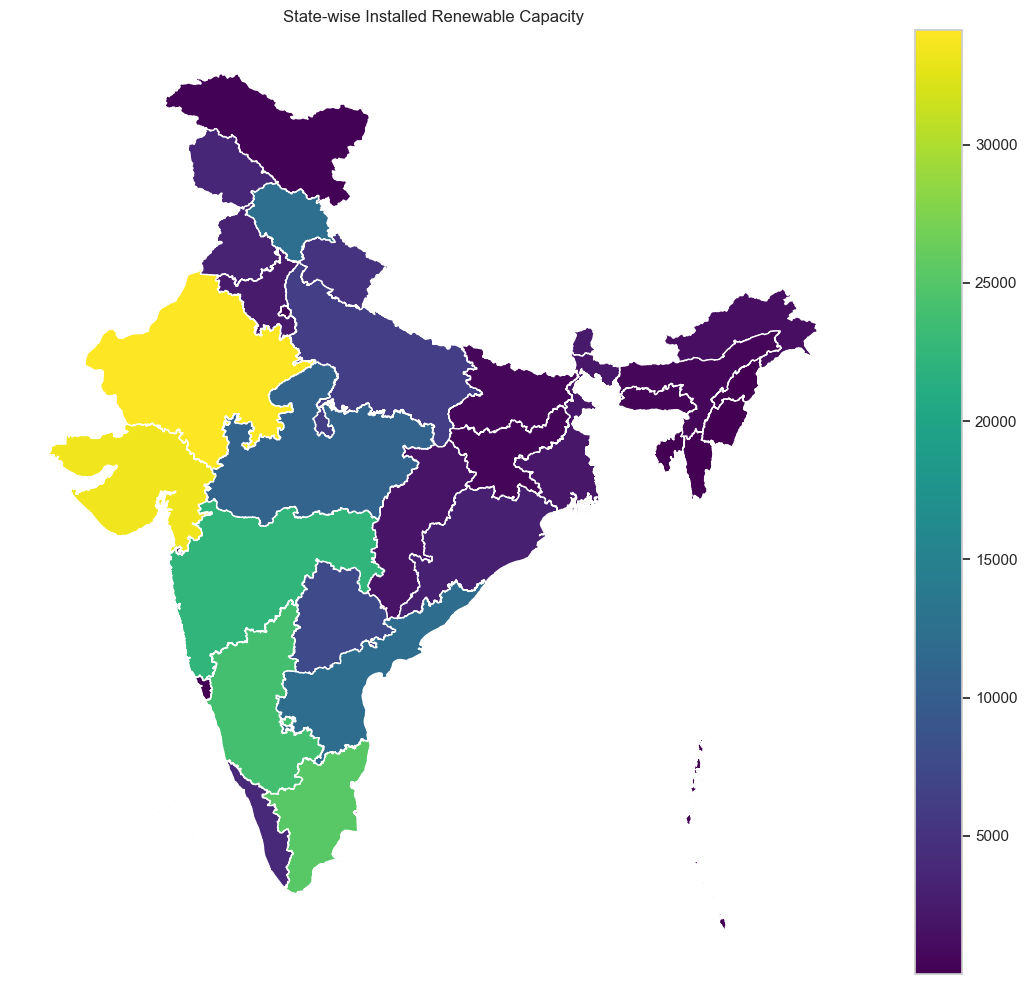

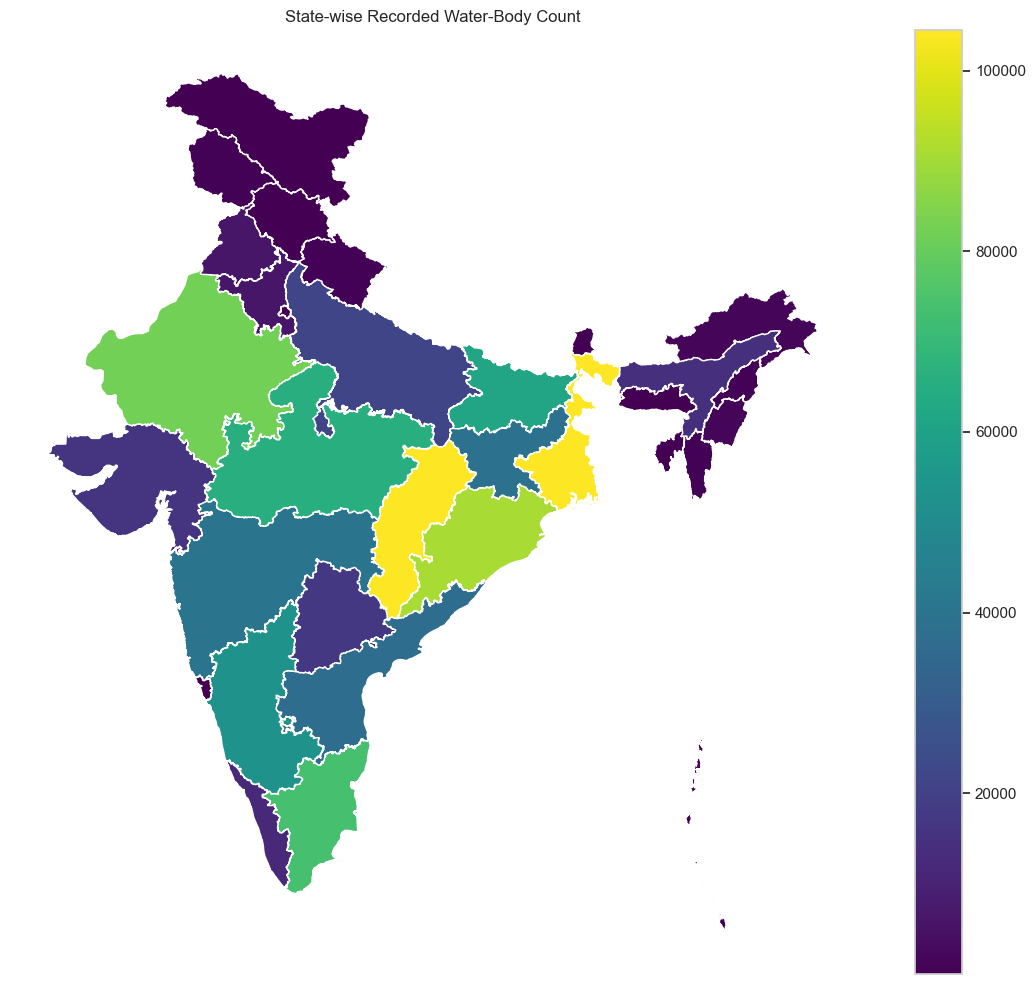

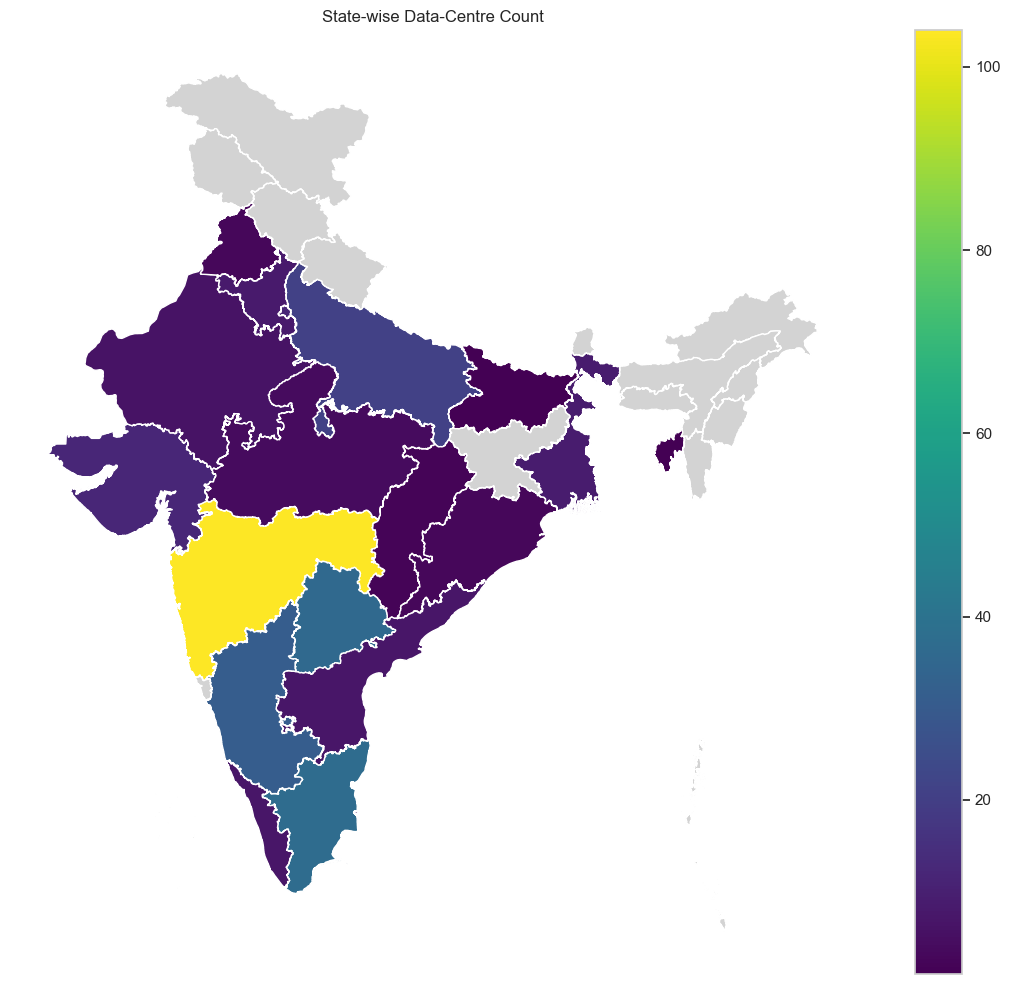

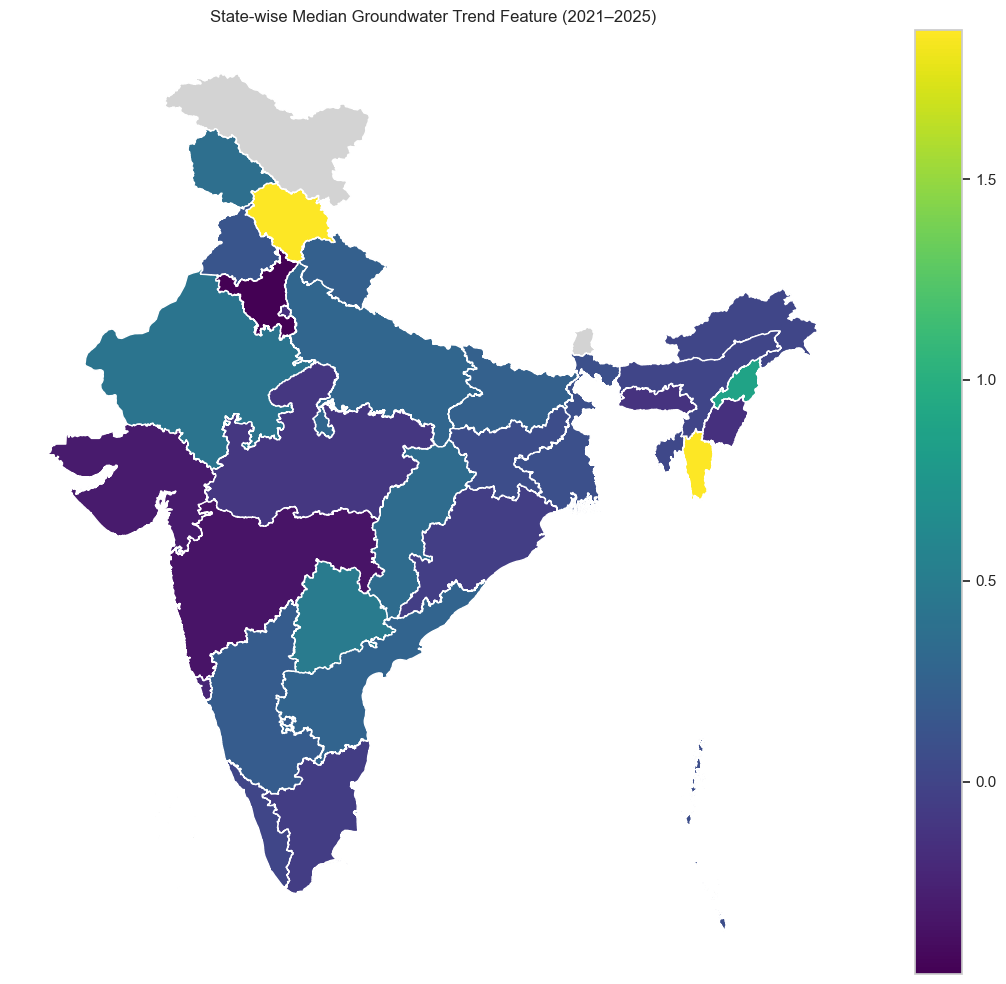

In [51]:
def state_map(value_col, title, legend_label=None):
    if gdf is None:
        print("GeoJSON unavailable.")
        return

    map_df = gdf.merge(
        integrated[["state_id", value_col]],
        on="state_id",
        how="left"
    )

    ax = map_df.plot(
        column=value_col,
        cmap="viridis",
        figsize=(12, 10),
        legend=True,
        missing_kwds={"color": "lightgrey", "label": "No data"}
    )
    ax.set_title(title)
    ax.axis("off")
    plt.tight_layout()
    plt.show()

state_map(
    "total_re_mw",
    "State-wise Installed Renewable Capacity"
)

state_map(
    "waterbody_count_total",
    "State-wise Recorded Water-Body Count"
)

state_map(
    "data_center_count",
    "State-wise Data-Centre Count"
)

state_map(
    "groundwater_median_trend_2021_2025",
    "State-wise Median Groundwater Trend Feature (2021–2025)"
)


# EDA Findings and Data Limitations

## 22. What to record after running the notebook

Use the plots/tables above to write concise evidence-based findings under these headings:

### Renewable energy
- Overall national capacity trajectory
- Years with relatively large additions
- States with the largest installed capacity
- States with the largest growth
- Technology mix differences
- Renewable potential concentration
- Headroom and utilization differences

### Electricity capacity and generation
- Regional installed-capacity composition
- Thermal vs non-fossil differences by region
- Regional generation levels
- Actual vs estimated generation differences
- Generation variability

### Groundwater
- Distribution of district-level trend values
- States with more negative/positive median trends
- Recent-vs-early changes
- Coverage limitations

### Water bodies
- States with the largest recorded counts
- Size-category distribution
- Density differences

### Data centres
- Concentration by market
- Concentration by state
- Descriptive relationships with resource indicators

### Integrated observations
- Strong or notable correlations
- States that appear unusual relative to others
- Variables that may deserve deeper analysis by the later project stages

Do **not** convert correlations or temporal coincidence into causal claims.


## 23. Important data limitations identified in the current package

### CEA installed-capacity data
The `State_UT` field contains repeated region/aggregate labels and truncated-looking labels in some rows. Regional `Grand Total` rows are therefore used for the cleanest regional comparison. State-level interpretation should be validated against the original CEA source before being used downstream.

### Data-centre data
`fact_market_datacentres.csv` is a market/state snapshot. It does not provide a historical yearly data-centre-growth series.

### Groundwater data
The groundwater dataset is district-level and contains summary/trend features. The numeric unit is not inferred by this notebook.

### Water bodies
Counts describe recorded water bodies, not water volume or directly usable industrial-water availability.

### Regional generation
Nuclear generation has missing values for some region/date combinations. Those missing observations are retained rather than being silently imputed.

### Renewable utilization
`renewable_utilization_pct` is used as supplied by `mnre_features`; the notebook does not redefine its denominator.


## 24. Suggested handoff to the rest of the team

The output of this notebook should provide:

1. Validated dataset coverage
2. Renewable-energy EDA
3. Thermal/non-fossil capacity EDA
4. Generation EDA
5. Groundwater EDA
6. Water-body EDA
7. Data-centre distribution EDA
8. Integrated state-level relationships
9. Candidate patterns worth investigating further
10. Explicit data limitations

The later stages can use these findings for:
- trend/change-point analysis
- policy/event investigation
- feature revalidation
- data-centre target construction
- ML
- explainability
- scenario analysis


## 25. Optional export of integrated EDA table

Run the next cell if you want a CSV containing the integrated state-level EDA features.

In [ ]:
# Uncomment to export:
#
# OUTPUT_DIR = DATA_DIR / "outputs"
# OUTPUT_DIR.mkdir(exist_ok=True)
# integrated.to_csv(OUTPUT_DIR / "integrated_state_eda.csv", index=False)
# quality_report.to_csv(OUTPUT_DIR / "data_quality_report.csv", index=False)
# national_re.to_csv(OUTPUT_DIR / "national_renewable_trend.csv", index=False)
# print("EDA tables exported to:", OUTPUT_DIR)
